# Deep Learning Numericals Solved by Hand: Neurons, Backprop, Optimizers and Training (Part 1)

> **Who is this for:** students preparing for deep-learning exams, quizzes and interviews, and any beginner who wants to *see* the arithmetic inside a neural network. Every problem uses tiny numbers, so you can solve it with pen, paper and a calculator.
>
> **What you will learn:**
> - how one neuron and the common activation functions (sigmoid, tanh, ReLU, Leaky ReLU, GELU) and their derivatives work, number by number
> - the perceptron learning rule, a computation graph, and one gradient step of logistic regression
> - softmax, cross-entropy, and the shape of every matrix in a vectorized deep network (including NumPy broadcasting)
> - a full forward pass **and** backpropagation through a 2-2-1 network, confirmed with gradient checking
> - vanishing and exploding gradients, Xavier/He initialization, input normalization, batch normalization (train and test time), dropout, L2 / weight decay and gradient clipping
> - mini-batches, exponentially weighted averages, SGD / momentum / RMSProp / Adam, the effect of the learning rate, learning-rate schedules and log-scale hyperparameter search
> - "structuring ML projects" numericals: data split sizes, single-number metrics, satisficing metrics, avoidable bias, variance, data mismatch and error-analysis ceilings
>
> **Prerequisites:** [PyTorch from zero](00_start_here_pytorch_from_zero.ipynb) (what a neuron, a loss and a gradient are) and [ML numericals solved by hand](../03_Machine_Learning/00c_ml_numericals_solved_by_hand.ipynb) (confusion matrix, precision, recall, F1). School algebra and "the slope of a curve" are enough: every formula is explained.
>
> **Time needed:** about 1 hour to read, 3-4 hours if you solve every "Try it yourself" problem on paper.
>
> **Runs on:** CPU, no API key, no internet. Only NumPy and matplotlib; the whole notebook runs in a few seconds.
>
> **Part 2:** CNNs, RNNs, LSTMs, attention, embeddings and perplexity are in [Deep learning numericals, part 2](00c_dl_numericals_part2_cnn_rnn_attention.ipynb).

## Explained simply

A neural network is a big calculator with many adjustable knobs (the **weights**). It multiplies inputs by the knobs, adds things up, squashes the result, and repeats. **Training** means turning every knob a little in the direction that makes the answers less wrong, again and again.

A **numerical** is an exam question that gives you concrete numbers ("the weights are 0.2 and 0.4, the input is 1.0...") and asks you to compute the output, the loss, a gradient or the next value of a weight. Doing a few of them by hand is like doing long division by hand once before you use a calculator: in real work PyTorch does the arithmetic, but after doing it yourself the formulas stop being magic, and you can tell when a result is nonsense.

**How to use this notebook.** For every section:

1. Read the **Problem** and try it on paper first (cover the solution).
2. Compare with **Solution by hand**, which shows every step and every intermediate number.
3. Run the **code cell**. It recomputes everything with NumPy and calls `check(...)`, which stops with an error if the code and the hand answer disagree. So every number written in this notebook has been verified.
4. Solve **Try it yourself**; the answer is hidden in a fold-out box.

**Rounding rule used everywhere:** numbers are *shown* rounded to 4 decimal places, but each step is calculated with the full, unrounded value of the previous step (the way a calculator's memory or "Ans" key works). If you round at every step, your last digit can differ by 1. That is normal and fine in an exam.

## Contents

| # | Section | Group |
|---|---|---|
| 0 | Setup | - |
| 1 | A single neuron | A. Neurons and losses |
| 2 | Activation functions and their derivatives | A |
| 3 | The perceptron learning rule (AND gate) | A |
| 4 | A computation graph: forward and backward | A |
| 5 | Logistic regression as one neuron: one gradient step | A |
| 6 | Softmax, cross-entropy and binary cross-entropy | A |
| 7 | Vectorization: shapes, broadcasting and batched gradients | B. Networks and backprop |
| 8 | Forward pass of a tiny 2-2-1 network | B |
| 9 | Backpropagation by hand for the 2-2-1 network | B |
| 10 | Gradient checking | B |
| 11 | Vanishing and exploding gradients | B |
| 12 | Weight initialization: Xavier and He | C. Making training work |
| 13 | Normalizing inputs | C |
| 14 | Batch normalization: training and test time | C |
| 15 | Dropout (inverted dropout) | C |
| 16 | L2 regularization, weight decay and gradient clipping | C |
| 17 | Mini-batches: iterations, epochs and updates | D. Optimization |
| 18 | Exponentially weighted averages | D |
| 19 | Optimizers: SGD, momentum, RMSProp, Adam | D |
| 20 | Learning rate: too small, good, too large | D |
| 21 | Learning-rate decay and schedules | D |
| 22 | Hyperparameter search on a log scale | D |
| 23 | Train / dev / test split sizes | E. Structuring ML projects |
| 24 | Single-number metric, optimizing and satisficing metrics | E |
| 25 | Human-level error, avoidable bias, variance and data mismatch | E |
| 26 | Error analysis: the ceiling on improvement | E |
| - | Recap cheat sheet, related notebooks, additional learning resources | - |

## 0. Setup

We import NumPy (arrays and maths) and matplotlib (plots), and fix the random **seed** so the few random checks print the same numbers on every run.

`check(name, numpy_value, hand_value)` is a tiny helper used in every section: it prints both numbers side by side and uses `np.isclose` to `assert` that they agree to 4 decimals (an absolute tolerance of 0.0001, which is exactly the rounding error of a 4-decimal answer). If an answer in the text were wrong, the notebook would stop with an error.

In [1]:
import math

import numpy as np
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)                  # seed NumPy's global random generator
rng = np.random.default_rng(SEED)     # a modern NumPy generator, used for the few random checks
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (7, 3), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})


def _fmt_float(v):
    v = float(v)
    if v != 0 and (abs(v) < 1e-3 or abs(v) >= 1e6):
        return f"{v:.4e}"             # very small or very large numbers: scientific notation
    return f"{v:.4f}"


def fmt(x):
    """Return a number or an array as one line of text with 4 decimals."""
    a = np.asarray(x, dtype=float)
    if a.ndim == 0:
        return _fmt_float(a)
    s = np.array2string(a, separator=", ", formatter={"float_kind": _fmt_float}, max_line_width=10_000)
    return " ".join(s.split())


def check(name, computed, hand, atol=1e-4, rtol=0.0):
    """Compare a NumPy result with the hand answer written in the markdown above it."""
    computed = np.asarray(computed, dtype=float)
    hand = np.asarray(hand, dtype=float)
    ok = computed.shape == hand.shape and bool(np.all(np.isclose(computed, hand, atol=atol, rtol=rtol)))
    print(f"{name:<34} numpy = {fmt(computed):<24} hand = {fmt(hand):<24} {'OK' if ok else 'MISMATCH'}")
    assert ok, f"{name}: NumPy gives {computed}, the hand answer is {hand}"


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


print("NumPy", np.__version__, "- helpers ready")

NumPy 2.1.3 - helpers ready


## 1. A single neuron

**What it is.** A neuron multiplies each input by a weight, adds the results, adds a **bias**, and passes the total $z$ through an **activation function** $f$:

$$z = w_1x_1 + w_2x_2 + \dots + w_nx_n + b = \mathbf{w}\cdot\mathbf{x} + b, \qquad a = f(z)$$

**Everyday analogy.** Deciding whether to go for a run: the inputs are "is it sunny?", "how tired am I?", "is a friend coming?". The weights say how much each one matters (tiredness counts *against*, so its weight is negative), the bias is your general mood, and the activation turns the total score into a decision or a confidence.

### Problem

A neuron has 3 inputs, weights and bias as below. Compute $z$ and the output $a$ for (a) sigmoid, (b) tanh, (c) ReLU.

| $i$ | input $x_i$ | weight $w_i$ |
|---|---|---|
| 1 | 2 | 0.5 |
| 2 | -1 | -0.4 |
| 3 | 3 | 0.2 |

Bias $b = 0.1$.

### Solution by hand

1. Multiply each input by its weight: $0.5\cdot 2 = 1.0$, $\;(-0.4)\cdot(-1) = 0.4$, $\;0.2\cdot 3 = 0.6$.
2. Add them and the bias: $z = 1.0 + 0.4 + 0.6 + 0.1 = 2.1$.
3. **Sigmoid** $\sigma(z) = \dfrac{1}{1+e^{-z}}$: $\;e^{-2.1} = 0.1225$, so $\sigma(2.1) = \dfrac{1}{1 + 0.1225} = 0.8909$.
4. **tanh** $\tanh(z) = \dfrac{e^{z}-e^{-z}}{e^{z}+e^{-z}}$: with a calculator, $\tanh(2.1) = 0.9705$.
5. **ReLU** $= \max(0, z) = \max(0, 2.1) = 2.1$.

**Answer:** $z = 2.1$; sigmoid $0.8909$, tanh $0.9705$, ReLU $2.1$.

In [2]:
x = np.array([2.0, -1.0, 3.0])
w = np.array([0.5, -0.4, 0.2])
b = 0.1

z = np.dot(w, x) + b
check("products w_i * x_i", w * x, [1.0, 0.4, 0.6])
check("z = w.x + b", z, 2.1)
check("e^(-z)", np.exp(-z), 0.1225)
check("sigmoid(z)", sigmoid(z), 0.8909)
check("tanh(z)", np.tanh(z), 0.9705)
check("ReLU(z)", max(0.0, z), 2.1)

products w_i * x_i                 numpy = [1.0000, 0.4000, 0.6000] hand = [1.0000, 0.4000, 0.6000] OK
z = w.x + b                        numpy = 2.1000                   hand = 2.1000                   OK
e^(-z)                             numpy = 0.1225                   hand = 0.1225                   OK
sigmoid(z)                         numpy = 0.8909                   hand = 0.8909                   OK
tanh(z)                            numpy = 0.9705                   hand = 0.9705                   OK
ReLU(z)                            numpy = 2.1000                   hand = 2.1000                   OK


### Try it yourself

A neuron has inputs $x = (1, 2)$, weights $w = (0.3, -0.6)$ and bias $b = 0.5$. Find $z$, $\sigma(z)$ and $\text{ReLU}(z)$.

<details><summary>Answer</summary>

$z = 0.3\cdot 1 + (-0.6)\cdot 2 + 0.5 = 0.3 - 1.2 + 0.5 = -0.4$.
$\sigma(-0.4) = 1/(1 + e^{0.4}) = 1/(1 + 1.4918) = 0.4013$. $\text{ReLU}(-0.4) = 0$.

</details>

**Common mistake:** forgetting the bias, or writing $e^{+z}$ instead of $e^{-z}$ in the sigmoid. **Exam tip:** $\sigma(z) > 0.5$ exactly when $z > 0$, a quick sanity check.

## 2. Activation functions and their derivatives

**What it is.** The activation function adds a *bend* (non-linearity). Without it, stacking layers is pointless: two linear layers in a row are just one linear layer. Backpropagation (Section 9) needs the **derivative** (slope) of each activation.

**Everyday analogy.** A light switch (step function) is either off or on. A dimmer (sigmoid, tanh) moves smoothly between the two. ReLU is a dimmer that stays fully off for negative inputs and passes positive inputs straight through.

| Function | $f(z)$ | $f'(z)$ | $f'$ written with the output $a = f(z)$ (used in backprop) |
|---|---|---|---|
| Sigmoid | $\dfrac{1}{1+e^{-z}}$ | $\sigma(z)\,(1-\sigma(z))$ | $a(1-a)$ |
| tanh | $\dfrac{e^{z}-e^{-z}}{e^{z}+e^{-z}}$ | $1-\tanh^2(z)$ | $1-a^2$ |
| ReLU | $\max(0,z)$ | $1$ if $z>0$, $0$ if $z<0$ | $1$ if $a>0$, else $0$ |
| Leaky ReLU ($\alpha = 0.01$) | $z$ if $z>0$, else $\alpha z$ | $1$ if $z>0$, else $\alpha$ | same |
| GELU | $z\,\Phi(z)$, $\Phi$ = standard normal CDF | (rarely asked by hand) | - |

At exactly $z = 0$ the ReLU slope is undefined; frameworks such as PyTorch simply use $0$ for ReLU and $\alpha$ for Leaky ReLU, and so do we.

### Problem

For $z \in \{-2, 0, 1, 2\}$ compute the value and the derivative of sigmoid, tanh, ReLU and Leaky ReLU ($\alpha = 0.01$). Bonus: GELU at $z = 1$ and $z = -1$.

### Solution by hand

1. **Sigmoid values.** $e^{2} = 7.3891$, so $\sigma(-2) = 1/8.3891 = 0.1192$. $\sigma(0) = 1/2 = 0.5$. $e^{-1} = 0.3679$, so $\sigma(1) = 1/(1 + e^{-1}) = 0.7311$. $e^{-2} = 0.1353$, so $\sigma(2) = 1/1.1353 = 0.8808$.
2. **Sigmoid slopes** $a(1-a)$: $0.1192\cdot 0.8808 = 0.1050$; $\;0.5\cdot 0.5 = 0.25$; $\;0.7311\cdot 0.2689 = 0.1966$; $\;0.8808\cdot 0.1192 = 0.1050$.
3. **tanh values** (calculator): $-0.9640,\ 0,\ 0.7616,\ 0.9640$.
4. **tanh slopes** $1 - a^2$: $1 - 0.9293 = 0.0707$; $\;1 - 0 = 1$; $\;1 - 0.5800 = 0.4200$; $\;0.0707$.
5. **ReLU:** values $0, 0, 1, 2$; slopes $0, 0, 1, 1$.
6. **Leaky ReLU:** values $0.01\cdot(-2) = -0.02$, $0$, $1$, $2$; slopes $0.01, 0.01, 1, 1$.
7. **GELU:** $\Phi(1) = 0.8413$, so $\text{GELU}(1) = 1\cdot 0.8413 = 0.8413$; $\;\Phi(-1) = 0.1587$, so $\text{GELU}(-1) = -0.1587$.

| $z$ | $\sigma$ | $\sigma'$ | $\tanh$ | $\tanh'$ | ReLU | ReLU$'$ | Leaky | Leaky$'$ |
|---|---|---|---|---|---|---|---|---|
| -2 | 0.1192 | 0.1050 | -0.9640 | 0.0707 | 0 | 0 | -0.02 | 0.01 |
| 0 | 0.5 | 0.25 | 0 | 1 | 0 | 0 | 0 | 0.01 |
| 1 | 0.7311 | 0.1966 | 0.7616 | 0.4200 | 1 | 1 | 1 | 1 |
| 2 | 0.8808 | 0.1050 | 0.9640 | 0.0707 | 2 | 1 | 2 | 1 |

Notice: the sigmoid slope is never above $0.25$ and tanh's never above $1$; both become tiny for large $|z|$ ("saturation"). That is the root of vanishing gradients (Section 11).

sigmoid                            numpy = [0.1192, 0.5000, 0.7311, 0.8808] hand = [0.1192, 0.5000, 0.7311, 0.8808] OK
sigmoid' = a(1-a)                  numpy = [0.1050, 0.2500, 0.1966, 0.1050] hand = [0.1050, 0.2500, 0.1966, 0.1050] OK
tanh                               numpy = [-0.9640, 0.0000, 0.7616, 0.9640] hand = [-0.9640, 0.0000, 0.7616, 0.9640] OK
tanh' = 1 - a^2                    numpy = [0.0707, 1.0000, 0.4200, 0.0707] hand = [0.0707, 1.0000, 0.4200, 0.0707] OK
ReLU                               numpy = [0.0000, 0.0000, 1.0000, 2.0000] hand = [0.0000, 0.0000, 1.0000, 2.0000] OK
ReLU'                              numpy = [0.0000, 0.0000, 1.0000, 1.0000] hand = [0.0000, 0.0000, 1.0000, 1.0000] OK
Leaky ReLU                         numpy = [-0.0200, 0.0000, 1.0000, 2.0000] hand = [-0.0200, 0.0000, 1.0000, 2.0000] OK
Leaky ReLU'                        numpy = [0.0100, 0.0100, 1.0000, 1.0000] hand = [0.0100, 0.0100, 1.0000, 1.0000] OK
GELU(1), GELU(-1)                  numpy = [

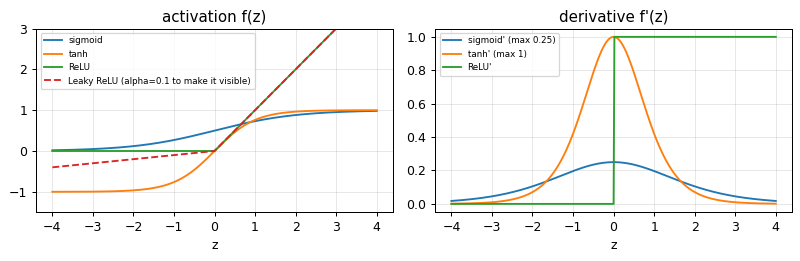

In [3]:
z = np.array([-2.0, 0.0, 1.0, 2.0])
alpha = 0.01

s = sigmoid(z)
t = np.tanh(z)
relu = np.maximum(0, z)
relu_grad = (z > 0).astype(float)                 # slope 0 at z = 0 (PyTorch convention)
leaky = np.where(z > 0, z, alpha * z)
leaky_grad = np.where(z > 0, 1.0, alpha)
gelu = lambda v: 0.5 * v * (1 + math.erf(v / math.sqrt(2)))   # exact GELU with the error function

check("sigmoid", s, [0.1192, 0.5, 0.7311, 0.8808])
check("sigmoid' = a(1-a)", s * (1 - s), [0.1050, 0.25, 0.1966, 0.1050])
check("tanh", t, [-0.9640, 0.0, 0.7616, 0.9640])
check("tanh' = 1 - a^2", 1 - t**2, [0.0707, 1.0, 0.4200, 0.0707])
check("ReLU", relu, [0, 0, 1, 2])
check("ReLU'", relu_grad, [0, 0, 1, 1])
check("Leaky ReLU", leaky, [-0.02, 0, 1, 2])
check("Leaky ReLU'", leaky_grad, [0.01, 0.01, 1, 1])
check("GELU(1), GELU(-1)", [gelu(1.0), gelu(-1.0)], [0.8413, -0.1587])

# Figure: the four activations and their slopes
zz = np.linspace(-4, 4, 401)
sz = sigmoid(zz)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3))
ax1.plot(zz, sz, label="sigmoid")
ax1.plot(zz, np.tanh(zz), label="tanh")
ax1.plot(zz, np.maximum(0, zz), label="ReLU")
ax1.plot(zz, np.where(zz > 0, zz, 0.1 * zz), "--", label="Leaky ReLU (alpha=0.1 to make it visible)")
ax1.set_ylim(-1.5, 3); ax1.set_title("activation f(z)"); ax1.legend(fontsize=7)
ax2.plot(zz, sz * (1 - sz), label="sigmoid' (max 0.25)")
ax2.plot(zz, 1 - np.tanh(zz) ** 2, label="tanh' (max 1)")
ax2.plot(zz, (zz > 0).astype(float), label="ReLU'")
ax2.set_title("derivative f'(z)"); ax2.legend(fontsize=7)
for ax in (ax1, ax2):
    ax.set_xlabel("z")
plt.tight_layout()
plt.show()

### Try it yourself

Compute value and derivative of sigmoid, tanh, ReLU and Leaky ReLU ($\alpha = 0.01$) at $z = -1$ and $z = 0.5$.

<details><summary>Answer</summary>

| $z$ | $\sigma$ | $\sigma'$ | $\tanh$ | $\tanh'$ | ReLU, ReLU$'$ | Leaky, Leaky$'$ |
|---|---|---|---|---|---|---|
| -1 | 0.2689 | 0.1966 | -0.7616 | 0.4200 | 0, 0 | -0.01, 0.01 |
| 0.5 | 0.6225 | 0.2350 | 0.4621 | 0.7864 | 0.5, 1 | 0.5, 1 |

</details>

**Exam tip:** in backprop you already have $a$ from the forward pass, so use the "written with $a$" column: $\sigma' = a(1-a)$, $\tanh' = 1-a^2$. Also useful: $\sigma(-z) = 1 - \sigma(z)$, so $\sigma'$ is symmetric around $0$.

## 3. The perceptron learning rule (AND gate)

**What it is.** A perceptron is a single neuron with a **step** activation: $\hat y = 1$ if $z \ge 0$, otherwise $\hat y = 0$. It learns with a very simple rule. For each example, compute the error $e = t - \hat y$ (target minus prediction), then

$$w_j \leftarrow w_j + \eta\, e\, x_j, \qquad b \leftarrow b + \eta\, e$$

When the prediction is right, $e = 0$ and nothing changes.

**Everyday analogy.** A teacher who only speaks up when you get an answer wrong, and then nudges you in the direction of the right answer.

### Problem

Train a perceptron on the AND gate. Start with $w_1 = 0.4$, $w_2 = 0.4$, $b = -0.1$, learning rate $\eta = 0.2$. Visit the four examples in the order shown, epoch after epoch, until one full epoch has no errors.

| $x_1$ | $x_2$ | target $t$ = $x_1$ AND $x_2$ |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 0 |
| 1 | 0 | 0 |
| 1 | 1 | 1 |

### Solution by hand

For each row: $z = w_1x_1 + w_2x_2 + b$, then $\hat y$, then $e = t - \hat y$, then the update $\Delta w_1 = \eta e x_1$, $\Delta w_2 = \eta e x_2$, $\Delta b = \eta e$. The last three columns are the weights **after** that row.

**Epoch 1** (start: $w = (0.4, 0.4)$, $b = -0.1$)

| $x_1, x_2$ | $t$ | $z$ | $\hat y$ | $e$ | $\Delta w_1, \Delta w_2, \Delta b$ | $w_1$ | $w_2$ | $b$ |
|---|---|---|---|---|---|---|---|---|
| 0, 0 | 0 | $-0.1$ | 0 | 0 | none | 0.4 | 0.4 | -0.1 |
| 0, 1 | 0 | $0.4 - 0.1 = 0.3$ | 1 | -1 | 0, -0.2, -0.2 | 0.4 | 0.2 | -0.3 |
| 1, 0 | 0 | $0.4 - 0.3 = 0.1$ | 1 | -1 | -0.2, 0, -0.2 | 0.2 | 0.2 | -0.5 |
| 1, 1 | 1 | $0.2 + 0.2 - 0.5 = -0.1$ | 0 | +1 | +0.2, +0.2, +0.2 | 0.4 | 0.4 | -0.3 |

**Epoch 2**

| $x_1, x_2$ | $t$ | $z$ | $\hat y$ | $e$ | $\Delta w_1, \Delta w_2, \Delta b$ | $w_1$ | $w_2$ | $b$ |
|---|---|---|---|---|---|---|---|---|
| 0, 0 | 0 | $-0.3$ | 0 | 0 | none | 0.4 | 0.4 | -0.3 |
| 0, 1 | 0 | $0.4 - 0.3 = 0.1$ | 1 | -1 | 0, -0.2, -0.2 | 0.4 | 0.2 | -0.5 |
| 1, 0 | 0 | $0.4 - 0.5 = -0.1$ | 0 | 0 | none | 0.4 | 0.2 | -0.5 |
| 1, 1 | 1 | $0.4 + 0.2 - 0.5 = 0.1$ | 1 | 0 | none | 0.4 | 0.2 | -0.5 |

**Epoch 3**: $z = -0.5,\ -0.3,\ -0.1,\ 0.1$ gives $\hat y = 0, 0, 0, 1$: all four correct, no updates. **Converged.**

**Answer:** final $w_1 = 0.4$, $w_2 = 0.2$, $b = -0.5$; errors per epoch $3, 1, 0$. The learned decision line is $0.4x_1 + 0.2x_2 - 0.5 = 0$: only the point $(1,1)$ lies on the positive side.

In [4]:
X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
t_and = np.array([0, 0, 0, 1])


def train_perceptron(X, t, w, b, eta, max_epochs=20, verbose=True):
    w = np.array(w, dtype=float)
    errors_per_epoch = []
    for epoch in range(1, max_epochs + 1):
        errors = 0
        for x_i, t_i in zip(X, t):
            z = w @ x_i + b
            y_hat = 1 if z >= 0 else 0
            e = t_i - y_hat
            w = w + eta * e * x_i
            b = b + eta * e
            errors += int(e != 0)
            if verbose:
                print(f"epoch {epoch}  x={x_i.astype(int)}  t={t_i}  z={z:+.1f}  y_hat={y_hat}  e={e:+d}"
                      f"  ->  w=({w[0]:.1f}, {w[1]:.1f})  b={b:+.1f}")
        errors_per_epoch.append(errors)
        if errors == 0:
            break
    return w, b, errors_per_epoch


w_final, b_final, errs = train_perceptron(X_and, t_and, w=[0.4, 0.4], b=-0.1, eta=0.2)
print()
check("final weights w1, w2", w_final, [0.4, 0.2])
check("final bias b", b_final, -0.5)
check("errors per epoch", errs, [3, 1, 0])

epoch 1  x=[0 0]  t=0  z=-0.1  y_hat=0  e=+0  ->  w=(0.4, 0.4)  b=-0.1
epoch 1  x=[0 1]  t=0  z=+0.3  y_hat=1  e=-1  ->  w=(0.4, 0.2)  b=-0.3
epoch 1  x=[1 0]  t=0  z=+0.1  y_hat=1  e=-1  ->  w=(0.2, 0.2)  b=-0.5
epoch 1  x=[1 1]  t=1  z=-0.1  y_hat=0  e=+1  ->  w=(0.4, 0.4)  b=-0.3
epoch 2  x=[0 0]  t=0  z=-0.3  y_hat=0  e=+0  ->  w=(0.4, 0.4)  b=-0.3
epoch 2  x=[0 1]  t=0  z=+0.1  y_hat=1  e=-1  ->  w=(0.4, 0.2)  b=-0.5
epoch 2  x=[1 0]  t=0  z=-0.1  y_hat=0  e=+0  ->  w=(0.4, 0.2)  b=-0.5
epoch 2  x=[1 1]  t=1  z=+0.1  y_hat=1  e=+0  ->  w=(0.4, 0.2)  b=-0.5
epoch 3  x=[0 0]  t=0  z=-0.5  y_hat=0  e=+0  ->  w=(0.4, 0.2)  b=-0.5
epoch 3  x=[0 1]  t=0  z=-0.3  y_hat=0  e=+0  ->  w=(0.4, 0.2)  b=-0.5
epoch 3  x=[1 0]  t=0  z=-0.1  y_hat=0  e=+0  ->  w=(0.4, 0.2)  b=-0.5
epoch 3  x=[1 1]  t=1  z=+0.1  y_hat=1  e=+0  ->  w=(0.4, 0.2)  b=-0.5

final weights w1, w2               numpy = [0.4000, 0.2000]         hand = [0.4000, 0.2000]         OK
final bias b                       numpy = -

### Try it yourself

Train a perceptron on the **OR** gate (targets $0, 1, 1, 1$ for the same four inputs, same order). Start from $w_1 = w_2 = 0$, $b = -0.3$, $\eta = 0.2$, same step rule. How many epochs until convergence, and what are the final weights?

<details><summary>Answer</summary>

Epoch 1: $(0,0)$: $z=-0.3$, correct. $(0,1)$: $z=-0.3 \Rightarrow \hat y=0$, $e=+1$, so $w=(0, 0.2)$, $b=-0.1$. $(1,0)$: $z=-0.1 \Rightarrow \hat y = 0$, $e=+1$, so $w=(0.2, 0.2)$, $b=0.1$. $(1,1)$: $z=0.5$, correct.
Epoch 2: $(0,0)$: $z=0.1 \Rightarrow \hat y=1$, $e=-1$, so $b=-0.1$. The other three are correct ($z = 0.1, 0.1, 0.3$).
Epoch 3: $z = -0.1, 0.1, 0.1, 0.3$, all correct.
**3 epochs** (errors $2, 1, 0$); final $w = (0.2, 0.2)$, $b = -0.1$.

</details>

**Exam tip:** the perceptron is guaranteed to converge only if the classes can be separated by a straight line (AND, OR: yes; **XOR: never**). XOR needs a hidden layer. **Common mistake:** forgetting to update the bias, or updating when the prediction was already correct.

## 4. A computation graph: forward and backward

**What it is.** A computation graph breaks a formula into small steps (nodes). The **forward pass** computes the values from left to right. The **backward pass** computes derivatives from right to left with the **chain rule**: the derivative with respect to an early variable is the product of the local derivatives along the path.

**Everyday analogy.** A relay race run backwards: the final runner hands a "blame score" to the runner before them, who multiplies it by how much they influenced the next runner, and so on back to the start.

### Problem

$J = \big((a + b)\cdot c\big)^2$ with $a = 1$, $b = 2$, $c = -0.5$. Use the steps $q = a + b$, $r = q\cdot c$, $J = r^2$. Compute $J$, then $\dfrac{\partial J}{\partial a}$, $\dfrac{\partial J}{\partial b}$, $\dfrac{\partial J}{\partial c}$. Check one derivative by nudging $a$ by $0.001$.

### Solution by hand

**Forward:**
1. $q = a + b = 1 + 2 = 3$
2. $r = q\cdot c = 3\cdot(-0.5) = -1.5$
3. $J = r^2 = 2.25$

**Backward** (local derivatives: $\partial J/\partial r = 2r$; $\partial r/\partial q = c$; $\partial r/\partial c = q$; $\partial q/\partial a = \partial q/\partial b = 1$):

4. $\dfrac{\partial J}{\partial r} = 2r = 2\cdot(-1.5) = -3$
5. $\dfrac{\partial J}{\partial q} = \dfrac{\partial J}{\partial r}\cdot c = -3\cdot(-0.5) = 1.5$
6. $\dfrac{\partial J}{\partial c} = \dfrac{\partial J}{\partial r}\cdot q = -3\cdot 3 = -9$
7. $\dfrac{\partial J}{\partial a} = \dfrac{\partial J}{\partial q}\cdot 1 = 1.5$ and $\dfrac{\partial J}{\partial b} = 1.5$

**Check by nudging:** with $a = 1.001$: $q = 3.001$, $r = -1.5005$, $J = 2.25150025$. $J$ grew by $0.00150025$, and $0.00150025/0.001 = 1.50025 \approx 1.5$, as $\partial J/\partial a = 1.5$ predicts. (The tiny extra $0.00025$ appears because a one-sided nudge is only approximate; Section 10 shows a more accurate two-sided version.)

In [5]:
a, b, c = 1.0, 2.0, -0.5
q = a + b
r = q * c
J = r**2

dJ_dr = 2 * r
dJ_dq = dJ_dr * c
dJ_dc = dJ_dr * q
dJ_da = dJ_dq * 1.0
dJ_db = dJ_dq * 1.0

check("q, r, J", [q, r, J], [3.0, -1.5, 2.25])
check("dJ/dr", dJ_dr, -3.0)
check("dJ/dq", dJ_dq, 1.5)
check("dJ/da, dJ/db, dJ/dc", [dJ_da, dJ_db, dJ_dc], [1.5, 1.5, -9.0])

J_nudged = ((a + 0.001 + b) * c) ** 2
check("J after nudging a by 0.001", J_nudged, 2.2515)
check("slope estimate (tolerance 0.001)", (J_nudged - J) / 0.001, 1.5, atol=1e-3)

q, r, J                            numpy = [3.0000, -1.5000, 2.2500] hand = [3.0000, -1.5000, 2.2500] OK
dJ/dr                              numpy = -3.0000                  hand = -3.0000                  OK
dJ/dq                              numpy = 1.5000                   hand = 1.5000                   OK
dJ/da, dJ/db, dJ/dc                numpy = [1.5000, 1.5000, -9.0000] hand = [1.5000, 1.5000, -9.0000] OK
J after nudging a by 0.001         numpy = 2.2515                   hand = 2.2515                   OK
slope estimate (tolerance 0.001)   numpy = 1.5002                   hand = 1.5000                   OK


### Try it yourself

Same graph, $J = \big((a+b)\cdot c\big)^2$, with $a = 3$, $b = -1$, $c = 1.5$. Find $J$ and all three partial derivatives.

<details><summary>Answer</summary>

$q = 2$, $r = 3$, $J = 9$. $\partial J/\partial r = 2r = 6$; $\partial J/\partial q = 6\cdot 1.5 = 9$, so $\partial J/\partial a = \partial J/\partial b = 9$; $\partial J/\partial c = 6\cdot q = 12$.

</details>

**Exam tip:** an **add** node copies the incoming gradient unchanged to both of its inputs; a **multiply** node sends each input the incoming gradient times the *other* input.

## 5. Logistic regression as one neuron: one gradient step

**What it is.** Logistic regression is a single neuron with a sigmoid and the **binary cross-entropy** (log) loss $L = -\big[y\ln a + (1-y)\ln(1-a)\big]$. For this pair the chain rule collapses to a famously simple result:

$$\frac{\partial L}{\partial a} = -\frac{y}{a} + \frac{1-y}{1-a}, \quad \frac{\partial a}{\partial z} = a(1-a) \quad\Longrightarrow\quad dz = \frac{\partial L}{\partial z} = a - y$$

Then $dw_j = x_j\,dz$, $db = dz$, and gradient descent updates $w \leftarrow w - \alpha\,dw$, $b \leftarrow b - \alpha\,db$ ($\alpha$ is the learning rate).

**Everyday analogy.** "Prediction minus truth" is how far off you were; each weight is blamed in proportion to how big its input was.

### Problem

One example $x = (1, 2)$, label $y = 1$. Current $w = (0.5, -0.25)$, $b = 0$, learning rate $\alpha = 0.1$. Do one gradient step and show that the loss goes down.

### Solution by hand

1. $z = 0.5\cdot 1 + (-0.25)\cdot 2 + 0 = 0.5 - 0.5 = 0$
2. $a = \sigma(0) = 0.5$
3. $L = -\ln 0.5 = 0.6931$
4. $dz = a - y = 0.5 - 1 = -0.5$
5. $dw_1 = x_1\,dz = 1\cdot(-0.5) = -0.5$; $\;dw_2 = x_2\,dz = 2\cdot(-0.5) = -1.0$; $\;db = -0.5$
6. Update: $w_1 = 0.5 - 0.1\cdot(-0.5) = 0.55$; $\;w_2 = -0.25 - 0.1\cdot(-1.0) = -0.15$; $\;b = 0 - 0.1\cdot(-0.5) = 0.05$
7. New forward pass: $z = 0.55\cdot 1 + (-0.15)\cdot 2 + 0.05 = 0.30$, $a = \sigma(0.3) = 0.5744$, $L = -\ln 0.5744 = 0.5544$.

**Answer:** the loss fell from $0.6931$ to $0.5544$.

In [6]:
x = np.array([1.0, 2.0]); y = 1.0
w = np.array([0.5, -0.25]); b = 0.0; lr = 0.1

bce = lambda a, y: -(y * np.log(a) + (1 - y) * np.log(1 - a))
z = w @ x + b
a = sigmoid(z)
dz = a - y
dw = x * dz
db = dz
check("z, a", [z, a], [0.0, 0.5])
check("loss before", bce(a, y), 0.6931)
check("dz = a - y", dz, -0.5)
check("dw", dw, [-0.5, -1.0])

w_new, b_new = w - lr * dw, b - lr * db
z_new = w_new @ x + b_new
a_new = sigmoid(z_new)
check("new w", w_new, [0.55, -0.15])
check("new b", b_new, 0.05)
check("new z, new a", [z_new, a_new], [0.30, 0.5744])
check("loss after", bce(a_new, y), 0.5544)

# dz = a - y really is the derivative: compare with a finite difference in z
eps = 1e-6
check("numerical dL/dz", (bce(sigmoid(z + eps), y) - bce(sigmoid(z - eps), y)) / (2 * eps), -0.5)

z, a                               numpy = [0.0000, 0.5000]         hand = [0.0000, 0.5000]         OK
loss before                        numpy = 0.6931                   hand = 0.6931                   OK
dz = a - y                         numpy = -0.5000                  hand = -0.5000                  OK
dw                                 numpy = [-0.5000, -1.0000]       hand = [-0.5000, -1.0000]       OK
new w                              numpy = [0.5500, -0.1500]        hand = [0.5500, -0.1500]        OK
new b                              numpy = 0.0500                   hand = 0.0500                   OK
new z, new a                       numpy = [0.3000, 0.5744]         hand = [0.3000, 0.5744]         OK
loss after                         numpy = 0.5544                   hand = 0.5544                   OK
numerical dL/dz                    numpy = -0.5000                  hand = -0.5000                  OK


### Try it yourself

Two examples, averaged (the cost is the mean loss, so gradients get a factor $\tfrac{1}{m}$): $x^{(1)} = (1, 0)$ with $y^{(1)} = 1$, and $x^{(2)} = (0, 1)$ with $y^{(2)} = 0$. Start from $w = (0, 0)$, $b = 0$, $\alpha = 1$. Compute $dw$, $db$, the new parameters, and the cost before and after.

<details><summary>Answer</summary>

Both $z = 0$, so $a = (0.5, 0.5)$ and $dz = a - y = (-0.5, 0.5)$.
$dw_1 = \tfrac12(1\cdot(-0.5) + 0\cdot 0.5) = -0.25$, $\;dw_2 = \tfrac12(0\cdot(-0.5) + 1\cdot 0.5) = 0.25$, $\;db = \tfrac12(-0.5 + 0.5) = 0$.
New $w = (0.25, -0.25)$, $b = 0$. Cost before $= 0.6931$. After: $a^{(1)} = \sigma(0.25) = 0.5622$, $a^{(2)} = \sigma(-0.25) = 0.4378$, cost $= -\tfrac12\big[\ln 0.5622 + \ln(1-0.4378)\big] = 0.5759$.

</details>

**Common mistake:** forgetting the $\tfrac{1}{m}$ when averaging gradients over $m$ examples.

## 6. Softmax, cross-entropy and binary cross-entropy

**What it is.** For $K$ classes the network outputs $K$ raw scores called **logits** $z_k$. **Softmax** turns them into probabilities that are positive and sum to 1:

$$p_k = \frac{e^{z_k}}{\sum_j e^{z_j}} = \frac{e^{z_k - \max z}}{\sum_j e^{z_j - \max z}}$$

Subtracting the maximum (the **max trick**) gives the same answer but stops $e^{z}$ from overflowing (for example $e^{1000}$ is infinity on a computer). **Categorical cross-entropy** is $L = -\ln p_{\text{true class}}$, and its gradient with respect to the logits is simply $p - y$ (with $y$ one-hot). For one sigmoid output $p$ and label $y \in \{0,1\}$, **binary cross-entropy** is $L = -\big[y\ln p + (1-y)\ln(1-p)\big]$.

**Everyday analogy.** Softmax is like sharing a pizza in proportion to how hungry everyone says they are, where "hunger" grows exponentially with the score. Cross-entropy is the "surprise" you feel at the true answer: low if you gave it high probability.

### Problem

(a) Logits for (cat, dog, bird) are $z = (2.0, 1.0, 0.1)$. Compute the softmax with the max trick.
(b) The cross-entropy if the true class is cat, and if it is bird.
(c) The gradient $p - y$ when the true class is cat.
(d) Binary cross-entropy for a sigmoid output $p = 0.8$ when $y = 1$ and when $y = 0$.

### Solution by hand

1. $\max z = 2.0$, so the shifted logits are $z - 2 = (0, -1, -1.9)$.
2. Exponentials: $e^{0} = 1$, $e^{-1} = 0.3679$, $e^{-1.9} = 0.1496$. Sum $= 1.5174$.
3. $p = (1, 0.3679, 0.1496)/1.5174 = (0.6590, 0.2424, 0.0986)$. They sum to 1. (Without the shift: $e^2 = 7.3891$, $e^1 = 2.7183$, $e^{0.1} = 1.1052$, sum $11.2125$, and $7.3891/11.2125 = 0.6590$: the same.)
4. True class cat: $L = -\ln 0.6590 = 0.4170$. True class bird: $L = -\ln p_{\text{bird}} = 2.3170$ (much more "surprised"). Careful: with the rounded $0.0986$ you would get $2.3167$; the logarithm of a small number magnifies rounding errors, so keep extra digits for small probabilities (or use the logsumexp check below).
5. Gradient for cat: $p - y = (0.6590 - 1,\ 0.2424 - 0,\ 0.0986 - 0) = (-0.3410, 0.2424, 0.0986)$. The negative entry pushes the cat logit up; the others are pushed down.
6. BCE with $p = 0.8$: $y = 1$: $-\ln 0.8 = 0.2231$; $\;y = 0$: $-\ln(1 - 0.8) = -\ln 0.2 = 1.6094$.

A neat check: $L = \text{logsumexp}(z) - z_{\text{true}}$ with $\text{logsumexp}(z) = 2 + \ln 1.5174 = 2.4170$. So $L_{\text{cat}} = 2.4170 - 2 = 0.4170$ and $L_{\text{bird}} = 2.4170 - 0.1 = 2.3170$.

In [7]:
z = np.array([2.0, 1.0, 0.1])
shifted = z - z.max()
e = np.exp(shifted)
p = e / e.sum()
check("shifted logits", shifted, [0.0, -1.0, -1.9])
check("exp(shifted)", e, [1.0, 0.3679, 0.1496])
check("sum of exps", e.sum(), 1.5174)
check("softmax p", p, [0.6590, 0.2424, 0.0986])
check("softmax without shift (same)", np.exp(z) / np.exp(z).sum(), [0.6590, 0.2424, 0.0986])
check("CE if true = cat", -np.log(p[0]), 0.4170)
check("CE if true = bird", -np.log(p[2]), 2.3170)
check("gradient p - y (cat)", p - np.array([1, 0, 0]), [-0.3410, 0.2424, 0.0986])
check("logsumexp(z)", z.max() + np.log(e.sum()), 2.4170)
check("BCE p=0.8, y=1", -np.log(0.8), 0.2231)
check("BCE p=0.8, y=0", -np.log(0.2), 1.6094)

try:
    import torch
    import torch.nn.functional as F
    ce_t = F.cross_entropy(torch.tensor([[2.0, 1.0, 0.1]]), torch.tensor([0])).item()
    bce_t = F.binary_cross_entropy(torch.tensor([0.8]), torch.tensor([1.0])).item()
    check("torch cross_entropy (cat)", ce_t, 0.4170)
    check("torch binary_cross_entropy", bce_t, 0.2231)
except ImportError:
    print("skipped: needs torch")

shifted logits                     numpy = [0.0000, -1.0000, -1.9000] hand = [0.0000, -1.0000, -1.9000] OK
exp(shifted)                       numpy = [1.0000, 0.3679, 0.1496] hand = [1.0000, 0.3679, 0.1496] OK
sum of exps                        numpy = 1.5174                   hand = 1.5174                   OK
softmax p                          numpy = [0.6590, 0.2424, 0.0986] hand = [0.6590, 0.2424, 0.0986] OK
softmax without shift (same)       numpy = [0.6590, 0.2424, 0.0986] hand = [0.6590, 0.2424, 0.0986] OK
CE if true = cat                   numpy = 0.4170                   hand = 0.4170                   OK
CE if true = bird                  numpy = 2.3170                   hand = 2.3170                   OK
gradient p - y (cat)               numpy = [-0.3410, 0.2424, 0.0986] hand = [-0.3410, 0.2424, 0.0986] OK
logsumexp(z)                       numpy = 2.4170                   hand = 2.4170                   OK
BCE p=0.8, y=1                     numpy = 0.2231                  

### Try it yourself

Logits $z = (1, 2, 3)$ and the true class is the third one. Compute the softmax and the cross-entropy. Also: BCE for $p = 0.3$ when $y = 1$ and when $y = 0$.

<details><summary>Answer</summary>

Shift by $3$: $(-2, -1, 0)$; exponentials $(0.1353, 0.3679, 1)$, sum $1.5032$; $p = (0.0900, 0.2447, 0.6652)$; $L = -\ln 0.6652 = 0.4076$.
BCE: $y=1$: $-\ln 0.3 = 1.2040$; $\;y=0$: $-\ln 0.7 = 0.3567$.

</details>

**Exam tip:** a freshly initialized classifier that guesses uniformly over $K$ classes has loss $\ln K$ (for 3 classes $\ln 3 = 1.0986$; for 10 classes $2.3026$). If your first training loss is far from this, something is off.

## 7. Vectorization: shapes, broadcasting and batched gradients

**What it is.** Real networks process $m$ examples at once with matrix products instead of Python loops. Most bugs in this step are **shape** bugs, so exams love shape questions. We use the "one column per example" convention common in course notes:

| Object | Shape | Meaning |
|---|---|---|
| $X = A^{[0]}$ | $(n_x, m)$ | $n_x$ features, $m$ examples (one per column) |
| $W^{[l]}$ | $(n^{[l]}, n^{[l-1]})$ | rows = units in this layer, columns = units in the previous layer |
| $b^{[l]}$ | $(n^{[l]}, 1)$ | one bias per unit, **broadcast** across the $m$ columns |
| $Z^{[l]} = W^{[l]}A^{[l-1]} + b^{[l]}$, $A^{[l]} = g(Z^{[l]})$ | $(n^{[l]}, m)$ | one column per example |
| $dW^{[l]}$, $db^{[l]}$ | same as $W^{[l]}$, $b^{[l]}$ | a gradient always has the shape of the thing it is the gradient of |

(PyTorch stores data the other way round, one **row** per example, shape $(m, n)$, and `nn.Linear` computes $XW^\top + b$ with `weight` of shape (out, in). The numbers are the same, only transposed.)

**Broadcasting** means NumPy automatically "stretches" an array of size 1 along a dimension to match the other array, like copying the bias column once for every example.

**Everyday analogy.** A spreadsheet: each column is one customer, each row one feature. Adding a bias column is like adding the same "delivery fee" to every customer's row total.

### Problem

(a) A network has layer sizes $[n_x, n^{[1]}, n^{[2]}, n^{[3]}] = [4, 5, 3, 1]$ and a batch of $m = 10$ examples. Give the shapes of $W^{[l]}, b^{[l]}, Z^{[l]}, A^{[l]}, dW^{[l]}$ and the total number of parameters.

(b) Broadcasting: compute $Z = WX + b$ with

$$W = \begin{pmatrix} 1 & 0 \\ 2 & -1 \end{pmatrix},\quad X = \begin{pmatrix} 1 & 2 & 3 \\ 0 & 1 & 2 \end{pmatrix},\quad b = \begin{pmatrix} 0.5 \\ -1 \end{pmatrix}$$

(c) Batched gradients: a sigmoid output unit with weights $W$ of shape $(1, 2)$ sees the same $X$ (2 features, $m = 3$ examples). Its outputs are $A = (0.8, 0.4, 0.6)$ and the labels are $Y = (1, 0, 1)$. With cross-entropy, compute $dZ = A - Y$, $dW = \frac{1}{m}\,dZ\,X^\top$ and $db = \frac{1}{m}\sum dZ$.

### Solution by hand

**(a)** For each layer, parameters $= n^{[l]}\cdot n^{[l-1]} + n^{[l]}$:

| $l$ | $W^{[l]}$ and $dW^{[l]}$ | $b^{[l]}$ | $Z^{[l]}$, $A^{[l]}$ | parameters |
|---|---|---|---|---|
| 1 | $(5, 4)$ | $(5, 1)$ | $(5, 10)$ | $5\cdot 4 + 5 = 25$ |
| 2 | $(3, 5)$ | $(3, 1)$ | $(3, 10)$ | $3\cdot 5 + 3 = 18$ |
| 3 | $(1, 3)$ | $(1, 1)$ | $(1, 10)$ | $1\cdot 3 + 1 = 4$ |

Total $= 25 + 18 + 4 = 47$ parameters. Note that $m$ never appears in a parameter shape: the same weights are used for every example.

**(b)** $WX$ is $(2,2)\times(2,3) = (2,3)$. Row 1 of $W$ is $(1, 0)$: dot it with each column of $X$: $(1\cdot1 + 0\cdot0,\ 1\cdot2 + 0\cdot1,\ 1\cdot3 + 0\cdot2) = (1, 2, 3)$. Row 2 is $(2, -1)$: $(2\cdot1 - 0,\ 2\cdot2 - 1,\ 2\cdot3 - 2) = (2, 3, 4)$. Now $b$ has shape $(2, 1)$, so it is copied to all 3 columns:

$$Z = \begin{pmatrix} 1 & 2 & 3 \\ 2 & 3 & 4 \end{pmatrix} + \begin{pmatrix} 0.5 & 0.5 & 0.5 \\ -1 & -1 & -1 \end{pmatrix} = \begin{pmatrix} 1.5 & 2.5 & 3.5 \\ 1 & 2 & 3 \end{pmatrix}$$

**(c)**
1. $dZ = A - Y = (0.8 - 1,\ 0.4 - 0,\ 0.6 - 1) = (-0.2, 0.4, -0.4)$, shape $(1, 3)$.
2. $dZ\,X^\top$ has shape $(1,3)\times(3,2) = (1,2)$: first entry $(-0.2)\cdot1 + 0.4\cdot2 + (-0.4)\cdot3 = -0.2 + 0.8 - 1.2 = -0.6$; second entry $(-0.2)\cdot0 + 0.4\cdot1 + (-0.4)\cdot2 = 0 + 0.4 - 0.8 = -0.4$.
3. $dW = \tfrac13(-0.6, -0.4) = (-0.2, -0.1333)$, the same shape $(1, 2)$ as $W$.
4. $db = \tfrac13(-0.2 + 0.4 - 0.4) = \tfrac13(-0.2) = -0.0667$.

In [8]:
# (a) shapes and parameter count of a [4, 5, 3, 1] network with m = 10
sizes, m = [4, 5, 3, 1], 10
A = rng.normal(size=(sizes[0], m))                    # X = A[0]
total = 0
for l in range(1, len(sizes)):
    W = rng.normal(size=(sizes[l], sizes[l - 1])) * 0.1
    b_l = np.zeros((sizes[l], 1))
    Z = W @ A + b_l                                   # broadcasting adds b to every column
    A = np.tanh(Z)
    n_params = W.size + b_l.size
    total += n_params
    print(f"layer {l}: W{W.shape}  b{b_l.shape}  Z,A{Z.shape}  dW{W.shape}  params={n_params}")
assert A.shape == (1, 10)
check("total parameters", total, 47)

# (b) broadcasting b of shape (2, 1) across m = 3 columns
W = np.array([[1.0, 0.0], [2.0, -1.0]])
X = np.array([[1.0, 2.0, 3.0], [0.0, 1.0, 2.0]])
b = np.array([[0.5], [-1.0]])
check("W @ X", W @ X, [[1, 2, 3], [2, 3, 4]])
check("Z = W @ X + b", W @ X + b, [[1.5, 2.5, 3.5], [1.0, 2.0, 3.0]])

# (c) batched gradients for a sigmoid output unit
A_out = np.array([[0.8, 0.4, 0.6]])
Y = np.array([[1.0, 0.0, 1.0]])
dZ = A_out - Y
dW = (dZ @ X.T) / 3
db = dZ.sum(axis=1, keepdims=True) / 3
check("dZ = A - Y", dZ, [[-0.2, 0.4, -0.4]])
check("dZ @ X.T", dZ @ X.T, [[-0.6, -0.4]])
check("dW = (1/m) dZ X^T", dW, [[-0.2, -0.1333]])
check("db = (1/m) sum(dZ)", db, [[-0.0667]])
print("shape of dW:", dW.shape, "| shape of db:", db.shape)

layer 1: W(5, 4)  b(5, 1)  Z,A(5, 10)  dW(5, 4)  params=25
layer 2: W(3, 5)  b(3, 1)  Z,A(3, 10)  dW(3, 5)  params=18
layer 3: W(1, 3)  b(1, 1)  Z,A(1, 10)  dW(1, 3)  params=4
total parameters                   numpy = 47.0000                  hand = 47.0000                  OK
W @ X                              numpy = [[1.0000, 2.0000, 3.0000], [2.0000, 3.0000, 4.0000]] hand = [[1.0000, 2.0000, 3.0000], [2.0000, 3.0000, 4.0000]] OK
Z = W @ X + b                      numpy = [[1.5000, 2.5000, 3.5000], [1.0000, 2.0000, 3.0000]] hand = [[1.5000, 2.5000, 3.5000], [1.0000, 2.0000, 3.0000]] OK
dZ = A - Y                         numpy = [[-0.2000, 0.4000, -0.4000]] hand = [[-0.2000, 0.4000, -0.4000]] OK
dZ @ X.T                           numpy = [[-0.6000, -0.4000]]     hand = [[-0.6000, -0.4000]]     OK
dW = (1/m) dZ X^T                  numpy = [[-0.2000, -0.1333]]     hand = [[-0.2000, -0.1333]]     OK
db = (1/m) sum(dZ)                 numpy = [[-0.0667]]              hand = [[-0.0667]]

### Try it yourself

(a) Layer sizes $[3, 4, 4, 2]$ with $m = 32$: give the shapes of $W^{[1]}, Z^{[2]}, b^{[3]}, A^{[3]}$ and the total number of parameters.
(b) With the same $X$ as in (c), outputs $A = (0.9, 0.2, 0.7)$ and labels $Y = (1, 0, 0)$: compute $dW$ and $db$.

<details><summary>Answer</summary>

(a) $W^{[1]}$: $(4, 3)$; $Z^{[2]}$: $(4, 32)$; $b^{[3]}$: $(2, 1)$; $A^{[3]}$: $(2, 32)$. Parameters: $(4\cdot3+4) + (4\cdot4+4) + (2\cdot4+2) = 16 + 20 + 10 = 46$.
(b) $dZ = (-0.1, 0.2, 0.7)$; $dZ\,X^\top = (-0.1 + 0.4 + 2.1,\ 0 + 0.2 + 1.4) = (2.4, 1.6)$; $dW = (0.8, 0.5333)$; $db = 0.8/3 = 0.2667$.

</details>

**Common mistake:** creating the bias with shape `(n,)` instead of `(n, 1)`. NumPy treats `(n,)` as a *row*, so adding it to an `(n, m)` array either fails, or (when $n = m$) silently adds the wrong numbers. Use `keepdims=True` when summing for $db$.

## 8. Forward pass of a tiny 2-2-1 network

**What it is.** A **forward pass** pushes the inputs through the network layer by layer to get a prediction and a loss. Here: 2 inputs, a hidden layer of 2 sigmoid units, and 1 sigmoid output.

```
 layer 0 (inputs)      layer 1 (hidden, sigmoid)      layer 2 (output, sigmoid)
 x1 --w1--> h1 <--w2-- x2
 x1 --w3--> h2 <--w4-- x2
                       h1 --w5--> y_hat <--w6-- h2
```

Each hidden unit sees both inputs: $h_1$ uses $w_1, w_2, b_1$ and $h_2$ uses $w_3, w_4, b_2$; the output uses $w_5, w_6, b_3$.

**Everyday analogy.** A small company: two managers (hidden units) each read both reports (inputs) and form an opinion; the CEO (output) combines the two opinions into one decision.

### Problem

Input $x = (x_1, x_2) = (1.0, 0.5)$, target $y = 1$. Loss $L = \tfrac12(\hat y - y)^2$ (squared error; the $\tfrac12$ makes the derivative neat). Also report the binary cross-entropy.

| Parameter | Connection | Value |
|---|---|---|
| $w_1$ | $x_1 \to h_1$ | 0.2 |
| $w_2$ | $x_2 \to h_1$ | 0.4 |
| $w_3$ | $x_1 \to h_2$ | -0.3 |
| $w_4$ | $x_2 \to h_2$ | 0.1 |
| $b_1$, $b_2$ | hidden biases | 0.1, 0.2 |
| $w_5$ | $h_1 \to \hat y$ | 0.5 |
| $w_6$ | $h_2 \to \hat y$ | -0.6 |
| $b_3$ | output bias | 0.1 |

### Solution by hand

1. $z_{h1} = w_1x_1 + w_2x_2 + b_1 = 0.2\cdot1.0 + 0.4\cdot0.5 + 0.1 = 0.2 + 0.2 + 0.1 = 0.5$, so $h_1 = \sigma(0.5) = 0.6225$
2. $z_{h2} = w_3x_1 + w_4x_2 + b_2 = -0.3\cdot1.0 + 0.1\cdot0.5 + 0.2 = -0.3 + 0.05 + 0.2 = -0.05$, so $h_2 = \sigma(-0.05) = 0.4875$
3. $z_o = w_5h_1 + w_6h_2 + b_3 = 0.5\cdot0.6225 + (-0.6)\cdot0.4875 + 0.1 = 0.3112 - 0.2925 + 0.1 = 0.1187$
4. $\hat y = \sigma(0.1187) = 0.5296$
5. $L = \tfrac12(0.5296 - 1)^2 = \tfrac12(-0.4704)^2 = \tfrac12\cdot 0.2212 = 0.1106$
6. Cross-entropy instead: $-\ln 0.5296 = 0.6355$

**Answer:** $\hat y = 0.5296$, squared-error loss $0.1106$ (cross-entropy $0.6355$). The prediction is barely above one half although the target is 1, so there is a lot to learn.

In [9]:
x1, x2, y = 1.0, 0.5, 1.0
params = dict(w1=0.2, w2=0.4, w3=-0.3, w4=0.1, b1=0.1, b2=0.2, w5=0.5, w6=-0.6, b3=0.1)


def forward_221(p, x1=x1, x2=x2, y=y):
    """Forward pass of the 2-2-1 sigmoid network; returns every intermediate value."""
    f = {}
    f["z_h1"] = p["w1"] * x1 + p["w2"] * x2 + p["b1"]
    f["z_h2"] = p["w3"] * x1 + p["w4"] * x2 + p["b2"]
    f["h1"], f["h2"] = sigmoid(f["z_h1"]), sigmoid(f["z_h2"])
    f["z_o"] = p["w5"] * f["h1"] + p["w6"] * f["h2"] + p["b3"]
    f["y_hat"] = sigmoid(f["z_o"])
    f["L"] = 0.5 * (f["y_hat"] - y) ** 2
    return f


f = forward_221(params)
check("z_h1, h1", [f["z_h1"], f["h1"]], [0.5, 0.6225])
check("z_h2, h2", [f["z_h2"], f["h2"]], [-0.05, 0.4875])
check("w5*h1, w6*h2", [params["w5"] * f["h1"], params["w6"] * f["h2"]], [0.3112, -0.2925])
check("z_o", f["z_o"], 0.1187)
check("y_hat", f["y_hat"], 0.5296)
check("L = 0.5 (y_hat - y)^2", f["L"], 0.1106)
check("cross-entropy -ln(y_hat)", -np.log(f["y_hat"]), 0.6355)

z_h1, h1                           numpy = [0.5000, 0.6225]         hand = [0.5000, 0.6225]         OK
z_h2, h2                           numpy = [-0.0500, 0.4875]        hand = [-0.0500, 0.4875]        OK
w5*h1, w6*h2                       numpy = [0.3112, -0.2925]        hand = [0.3112, -0.2925]        OK
z_o                                numpy = 0.1187                   hand = 0.1187                   OK
y_hat                              numpy = 0.5296                   hand = 0.5296                   OK
L = 0.5 (y_hat - y)^2              numpy = 0.1106                   hand = 0.1106                   OK
cross-entropy -ln(y_hat)           numpy = 0.6355                   hand = 0.6355                   OK


### Try it yourself

Same weights, but now the input is $x = (0, 1)$ with target $y = 0$. Compute $h_1$, $h_2$, $\hat y$ and $L = \tfrac12(\hat y - y)^2$.

<details><summary>Answer</summary>

$z_{h1} = 0.4 + 0.1 = 0.5$, $h_1 = 0.6225$. $z_{h2} = 0.1 + 0.2 = 0.3$, $h_2 = \sigma(0.3) = 0.5744$. $z_o = 0.5\cdot0.6225 - 0.6\cdot0.5744 + 0.1 = 0.3112 - 0.3447 + 0.1 = 0.0666$, $\hat y = \sigma(0.0666) = 0.5166$, $L = \tfrac12(0.5166)^2 = 0.1334$.

</details>

**Common mistake:** mixing up which weight connects which pair of units. Draw the network and write each weight on its arrow before you start.

## 9. Backpropagation by hand for the 2-2-1 network

**What it is.** **Backpropagation** applies the chain rule from the loss back to every weight, reusing the values saved during the forward pass. Then **gradient descent** moves each weight a little against its gradient: $w \leftarrow w - \eta\,\dfrac{\partial L}{\partial w}$.

**Everyday analogy.** After a bad quarter, the CEO works out how much each manager's opinion contributed to the mistake, and each manager in turn works out how much each report they read contributed. Everyone adjusts in proportion to their share of the blame.

The key quantity is the "error signal" $\delta$ of a unit, $\delta = \partial L/\partial z$ (the gradient with respect to that unit's weighted sum). With sigmoid units:

$$\delta_o = (\hat y - y)\,\hat y(1-\hat y), \qquad \delta_{h1} = \delta_o\, w_5\, h_1(1-h_1), \qquad \delta_{h2} = \delta_o\, w_6\, h_2(1-h_2)$$

and the gradient of any weight is ($\delta$ of the unit it feeds into) $\times$ (the input it carries).

### Problem

Using the forward pass of Section 8 ($h_1 = 0.6225$, $h_2 = 0.4875$, $\hat y = 0.5296$, $L = 0.1106$), compute every partial derivative, do one gradient-descent step with $\eta = 0.5$, and show that the loss decreases on the next forward pass.

### Solution by hand

**Output layer**
1. $\dfrac{\partial L}{\partial \hat y} = \hat y - y = 0.5296 - 1 = -0.4704$
2. $\dfrac{\partial \hat y}{\partial z_o} = \hat y(1-\hat y) = 0.5296\cdot0.4704 = 0.2491$
3. $\delta_o = \dfrac{\partial L}{\partial z_o} = -0.4704\cdot0.2491 = -0.1172$
4. $\dfrac{\partial L}{\partial w_5} = \delta_o h_1 = -0.1172\cdot0.6225 = -0.0729$; $\;\dfrac{\partial L}{\partial w_6} = \delta_o h_2 = -0.1172\cdot0.4875 = -0.0571$; $\;\dfrac{\partial L}{\partial b_3} = \delta_o = -0.1172$

**Hidden layer** (use the **old** $w_5$, $w_6$)

5. $\dfrac{\partial L}{\partial h_1} = \delta_o w_5 = -0.1172\cdot0.5 = -0.0586$; $\;\dfrac{\partial L}{\partial h_2} = \delta_o w_6 = -0.1172\cdot(-0.6) = 0.0703$
6. $h_1(1-h_1) = 0.6225\cdot0.3775 = 0.2350$ and $h_2(1-h_2) = 0.4875\cdot0.5125 = 0.2498$
7. $\delta_{h1} = -0.0586\cdot0.2350 = -0.0138$; $\;\delta_{h2} = 0.0703\cdot0.2498 = 0.0176$
8. $\dfrac{\partial L}{\partial w_1} = \delta_{h1}x_1 = -0.0138$; $\;\dfrac{\partial L}{\partial w_2} = \delta_{h1}x_2 = -0.0138\cdot0.5 = -0.0069$; $\;\dfrac{\partial L}{\partial b_1} = -0.0138$
9. $\dfrac{\partial L}{\partial w_3} = \delta_{h2}x_1 = 0.0176$; $\;\dfrac{\partial L}{\partial w_4} = \delta_{h2}x_2 = 0.0088$; $\;\dfrac{\partial L}{\partial b_2} = 0.0176$

**Update** $w \leftarrow w - 0.5\cdot\text{gradient}$:

| Parameter | old | gradient | $-\eta\cdot$gradient | new |
|---|---|---|---|---|
| $w_1$ | 0.2 | -0.0138 | +0.0069 | 0.2069 |
| $w_2$ | 0.4 | -0.0069 | +0.0034 | 0.4034 |
| $w_3$ | -0.3 | 0.0176 | -0.0088 | -0.3088 |
| $w_4$ | 0.1 | 0.0088 | -0.0044 | 0.0956 |
| $b_1$ | 0.1 | -0.0138 | +0.0069 | 0.1069 |
| $b_2$ | 0.2 | 0.0176 | -0.0088 | 0.1912 |
| $w_5$ | 0.5 | -0.0729 | +0.0365 | 0.5365 |
| $w_6$ | -0.6 | -0.0571 | +0.0286 | -0.5714 |
| $b_3$ | 0.1 | -0.1172 | +0.0586 | 0.1586 |

**New forward pass:** $z_{h1} = 0.5155$, $h_1 = 0.6261$; $z_{h2} = -0.0698$, $h_2 = 0.4826$; $z_o = 0.5365\cdot0.6261 - 0.5714\cdot0.4826 + 0.1586 = 0.2187$; $\hat y = 0.5545$; $L = \tfrac12(0.5545 - 1)^2 = 0.0993$.

**Answer:** the loss dropped from $0.1106$ to $0.0993$, and $\hat y$ moved from $0.5296$ towards the target, to $0.5545$. The output-layer weights changed most: they are closest to the error.

In [10]:
f = forward_221(params)
p = params

dL_dyhat = f["y_hat"] - y
dyhat_dzo = f["y_hat"] * (1 - f["y_hat"])
delta_o = dL_dyhat * dyhat_dzo
dL_dh1, dL_dh2 = delta_o * p["w5"], delta_o * p["w6"]          # OLD w5, w6
delta_h1 = dL_dh1 * f["h1"] * (1 - f["h1"])
delta_h2 = dL_dh2 * f["h2"] * (1 - f["h2"])

grads = dict(w1=delta_h1 * x1, w2=delta_h1 * x2, w3=delta_h2 * x1, w4=delta_h2 * x2,
             b1=delta_h1, b2=delta_h2, w5=delta_o * f["h1"], w6=delta_o * f["h2"], b3=delta_o)

check("dL/dy_hat", dL_dyhat, -0.4704)
check("dy_hat/dz_o = y_hat(1-y_hat)", dyhat_dzo, 0.2491)
check("delta_o", delta_o, -0.1172)
check("dL/dw5, dL/dw6, dL/db3", [grads["w5"], grads["w6"], grads["b3"]], [-0.0729, -0.0571, -0.1172])
check("dL/dh1, dL/dh2", [dL_dh1, dL_dh2], [-0.0586, 0.0703])
check("h1(1-h1), h2(1-h2)", [f["h1"] * (1 - f["h1"]), f["h2"] * (1 - f["h2"])], [0.2350, 0.2498])
check("delta_h1, delta_h2", [delta_h1, delta_h2], [-0.0138, 0.0176])
check("dL/dw1, dL/dw2, dL/db1", [grads["w1"], grads["w2"], grads["b1"]], [-0.0138, -0.0069, -0.0138])
check("dL/dw3, dL/dw4, dL/db2", [grads["w3"], grads["w4"], grads["b2"]], [0.0176, 0.0088, 0.0176])

# Finite-difference check of every gradient (Section 10 explains this idea)
eps = 1e-6
for name in params:
    plus, minus = dict(params), dict(params)
    plus[name] += eps
    minus[name] -= eps
    numeric = (forward_221(plus)["L"] - forward_221(minus)["L"]) / (2 * eps)
    assert np.isclose(numeric, grads[name], atol=1e-8), name
print("finite differences agree with every backprop gradient")

eta = 0.5
new_params = {k: params[k] - eta * grads[k] for k in params}
names = list(params)
check("new parameters (w1..b3)", [new_params[k] for k in names],
      [0.2069, 0.4034, -0.3088, 0.0956, 0.1069, 0.1912, 0.5365, -0.5714, 0.1586])

f_new = forward_221(new_params)
check("new z_h1, h1", [f_new["z_h1"], f_new["h1"]], [0.5155, 0.6261])
check("new z_h2, h2", [f_new["z_h2"], f_new["h2"]], [-0.0698, 0.4826])
check("new z_o, y_hat", [f_new["z_o"], f_new["y_hat"]], [0.2187, 0.5545])
check("new loss", f_new["L"], 0.0993)
assert f_new["L"] < f["L"]
print(f"loss went down: {f['L']:.4f} -> {f_new['L']:.4f}")

try:
    import torch
    t = {k: torch.tensor(v, dtype=torch.float64, requires_grad=True) for k, v in params.items()}
    h1_t = torch.sigmoid(t["w1"] * x1 + t["w2"] * x2 + t["b1"])
    h2_t = torch.sigmoid(t["w3"] * x1 + t["w4"] * x2 + t["b2"])
    yhat_t = torch.sigmoid(t["w5"] * h1_t + t["w6"] * h2_t + t["b3"])
    loss_t = 0.5 * (yhat_t - y) ** 2
    loss_t.backward()
    check("torch autograd gradients", [t[k].grad.item() for k in names], [grads[k] for k in names])
except ImportError:
    print("skipped: needs torch")

dL/dy_hat                          numpy = -0.4704                  hand = -0.4704                  OK
dy_hat/dz_o = y_hat(1-y_hat)       numpy = 0.2491                   hand = 0.2491                   OK
delta_o                            numpy = -0.1172                  hand = -0.1172                  OK
dL/dw5, dL/dw6, dL/db3             numpy = [-0.0729, -0.0571, -0.1172] hand = [-0.0729, -0.0571, -0.1172] OK
dL/dh1, dL/dh2                     numpy = [-0.0586, 0.0703]        hand = [-0.0586, 0.0703]        OK
h1(1-h1), h2(1-h2)                 numpy = [0.2350, 0.2498]         hand = [0.2350, 0.2498]         OK
delta_h1, delta_h2                 numpy = [-0.0138, 0.0176]        hand = [-0.0138, 0.0176]        OK
dL/dw1, dL/dw2, dL/db1             numpy = [-0.0138, -0.0069, -0.0138] hand = [-0.0138, -0.0069, -0.0138] OK
dL/dw3, dL/dw4, dL/db2             numpy = [0.0176, 0.0088, 0.0176] hand = [0.0176, 0.0088, 0.0176] OK
finite differences agree with every backprop gradient
new par

### Try it yourself

Repeat the output-layer and first hidden-unit gradients with **binary cross-entropy** $L = -\ln\hat y$ (target $y = 1$) instead of squared error. For a sigmoid output with cross-entropy, $\delta_o = \hat y - y$ (Section 5). Compute $\delta_o$, $\partial L/\partial w_5$, $\delta_{h1}$ and $\partial L/\partial w_1$.

<details><summary>Answer</summary>

$\delta_o = 0.5296 - 1 = -0.4704$ (no extra $\hat y(1-\hat y)$ factor). $\partial L/\partial w_5 = -0.4704\cdot0.6225 = -0.2928$. $\delta_{h1} = -0.4704\cdot0.5\cdot0.2350 = -0.0553$, so $\partial L/\partial w_1 = -0.0553\cdot1 = -0.0553$. The gradients are about 4 times larger than with squared error, because the factor $\hat y(1-\hat y) = 0.2491$ disappeared: one reason cross-entropy trains classifiers faster.

</details>

**Common mistake:** updating $w_5$ first and then using the *new* $w_5$ to compute $\delta_{h1}$. Compute **all** gradients with the old weights, then update everything at once.

## 10. Gradient checking

**What it is.** A test for your backprop code. Nudge one parameter up and down by a small $\varepsilon$, see how the cost changes, and compare with the analytic gradient:

$$g_{\text{num}} = \frac{J(\theta + \varepsilon) - J(\theta - \varepsilon)}{2\varepsilon}, \qquad \text{relative difference} = \frac{\lVert g_{\text{num}} - g_{\text{ana}}\rVert_2}{\lVert g_{\text{num}}\rVert_2 + \lVert g_{\text{ana}}\rVert_2}$$

The **two-sided** difference has an error proportional to $\varepsilon^2$, much better than the one-sided $\frac{J(\theta+\varepsilon) - J(\theta)}{\varepsilon}$ whose error is proportional to $\varepsilon$.

**Everyday analogy.** Checking a speedometer by timing how long the car takes between two road markers.

### Problem

(a) $J(\theta) = \theta^3$ at $\theta = 2$ with $\varepsilon = 0.01$: compare the two-sided and one-sided estimates with the true derivative $3\theta^2 = 12$.
(b) $J(\theta_1, \theta_2) = \theta_1^3 + \theta_1\theta_2$ at $(2, 1)$, $\varepsilon = 0.01$. The correct analytic gradient is $(3\theta_1^2 + \theta_2,\ \theta_1) = (13, 2)$. Compute the numerical gradient and the relative difference. Then do the same for a **buggy** analytic gradient $(12, 2)$ that forgot the $\theta_2$ term.

### Solution by hand

**(a)** $J(2.01) = 8.120601$ and $J(1.99) = 7.880599$ (exact).
1. Two-sided: $(8.120601 - 7.880599)/0.02 = 0.240002/0.02 = 12.0001$, error $0.0001$.
2. One-sided: $(8.120601 - 8)/0.01 = 12.0601$, error $0.0601$, about 600 times worse.

**(b)**
1. $\partial/\partial\theta_1$: $J(2.01, 1) = 8.120601 + 2.01 = 10.130601$ and $J(1.99, 1) = 7.880599 + 1.99 = 9.870599$, so $g_1 = 0.260002/0.02 = 13.0001$.
2. $\partial/\partial\theta_2$: $J(2, 1.01) = 8 + 2.02 = 10.02$ and $J(2, 0.99) = 9.98$, so $g_2 = 0.04/0.02 = 2.0000$.
3. Correct gradient: $\lVert g_{\text{num}} - g_{\text{ana}}\rVert = \lVert(0.0001, 0)\rVert = 0.0001$; $\lVert g_{\text{num}}\rVert = \sqrt{13.0001^2 + 2^2} = 13.1530$; $\lVert g_{\text{ana}}\rVert = \sqrt{173} = 13.1529$. Relative difference $= 0.0001/26.3060 = 3.8014\times10^{-6}$: tiny, the gradient is right.
4. Buggy gradient $(12, 2)$: difference $(1.0001, 0)$ with norm $1.0001$; $\lVert(12, 2)\rVert = \sqrt{148} = 12.1655$. Relative difference $= 1.0001/(13.1530 + 12.1655) = 0.0395$: far too large, there is a bug.

**Rule of thumb** (with a small $\varepsilon$ such as $10^{-7}$ in float64): a relative difference around $10^{-7}$ or smaller means the gradient is correct; around $10^{-3}$ or larger almost always means a bug. Values in between deserve a closer look. The exact thresholds vary between textbooks.

In [11]:
J = lambda th: th**3
eps = 0.01
two_sided = (J(2 + eps) - J(2 - eps)) / (2 * eps)
one_sided = (J(2 + eps) - J(2)) / eps
check("J(2.01), J(1.99)", [J(2.01), J(1.99)], [8.120601, 7.880599], atol=1e-9)
check("two-sided estimate", two_sided, 12.0001)
check("one-sided estimate", one_sided, 12.0601)

J2 = lambda th: th[0] ** 3 + th[0] * th[1]
theta = np.array([2.0, 1.0])
g_num = np.array([(J2(theta + eps * e) - J2(theta - eps * e)) / (2 * eps) for e in np.eye(2)])
g_ana = np.array([3 * theta[0] ** 2 + theta[1], theta[0]])
g_bug = np.array([3 * theta[0] ** 2, theta[0]])


def rel_diff(a, b):
    return np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b))


check("numerical gradient", g_num, [13.0001, 2.0])
check("norms of g_num, g_ana", [np.linalg.norm(g_num), np.linalg.norm(g_ana)], [13.1530, 13.1529])
check("relative difference (correct)", rel_diff(g_num, g_ana), 3.8014e-6, atol=0, rtol=1e-3)
check("relative difference (buggy)", rel_diff(g_num, g_bug), 0.0395)

eps_small = 1e-7
g_num_small = np.array([(J2(theta + eps_small * e) - J2(theta - eps_small * e)) / (2 * eps_small) for e in np.eye(2)])
print(f"with eps = 1e-7 the relative difference of the correct gradient is {rel_diff(g_num_small, g_ana):.1e}")

J(2.01), J(1.99)                   numpy = [8.1206, 7.8806]         hand = [8.1206, 7.8806]         OK
two-sided estimate                 numpy = 12.0001                  hand = 12.0001                  OK
one-sided estimate                 numpy = 12.0601                  hand = 12.0601                  OK
numerical gradient                 numpy = [13.0001, 2.0000]        hand = [13.0001, 2.0000]        OK
norms of g_num, g_ana              numpy = [13.1530, 13.1529]       hand = [13.1530, 13.1529]       OK
relative difference (correct)      numpy = 3.8014e-06               hand = 3.8014e-06               OK
relative difference (buggy)        numpy = 0.0395                   hand = 0.0395                   OK
with eps = 1e-7 the relative difference of the correct gradient is 3.7e-10


### Try it yourself

$J(\theta) = \theta^4$ at $\theta = 1$ with $\varepsilon = 0.01$. Compute the two-sided and one-sided estimates, and the relative difference between the two-sided estimate and the true derivative $4$ (for one number, the norm is just the absolute value).

<details><summary>Answer</summary>

$J(1.01) = 1.04060401$, $J(0.99) = 0.96059601$. Two-sided: $0.080008/0.02 = 4.0004$. One-sided: $0.04060401/0.01 = 4.0604$. Relative difference $= |4.0004 - 4|/(4.0004 + 4) = 0.0004/8.0004 = 5.0\times10^{-5}$.

</details>

**Exam tip:** gradient checking is slow (two forward passes per parameter), so use it only to debug, never during training. Switch off dropout while checking, and include the regularization term in $J$ if your gradients include it.

## 11. Vanishing and exploding gradients

**What it is.** Backprop multiplies one factor per layer. If the factors are smaller than 1, the gradient reaching the first layers **vanishes** (those layers stop learning); if they are larger than 1, it **explodes** (training becomes unstable, losses turn into NaN). The same happens to activations in the forward pass when every layer scales its input by more or less than 1.

**Everyday analogy.** The "telephone" game: if each person whispers a bit more quietly than they heard, the message disappears after 10 people; if each one shouts a bit louder, it soon becomes deafening.

### Problem

(a) In a deep sigmoid network (assume weights of 1), each layer multiplies the gradient by $\sigma'(z) \le 0.25$. In the *best* case, what fraction of the gradient survives 1, 2, 5, 10 and 20 layers? Compare with ReLU on active units.
(b) A deep linear network where every layer multiplies its input by $1.5$ (for example $W^{[l]} = 1.5\,I$), and another where every layer multiplies by $0.5$. What is the scale of the activations after $L = 10$ and $L = 50$ layers?

### Solution by hand

**(a)** The surviving fraction is $0.25^n$:

| layers $n$ | sigmoid (best case) $0.25^n$ | ReLU (active units) $1^n$ |
|---|---|---|
| 1 | 0.25 | 1 |
| 2 | 0.0625 | 1 |
| 5 | $0.25^5 = 9.7656\times10^{-4}$ (about 0.001) | 1 |
| 10 | $9.5367\times10^{-7}$ (about one millionth) | 1 |
| 20 | $9.0949\times10^{-13}$ | 1 |

**(b)** The scale is $1.5^L$ or $0.5^L$:

| $L$ | $1.5^L$ (explodes) | $0.5^L$ (vanishes) |
|---|---|---|
| 10 | 57.6650 | $9.7656\times10^{-4}$ |
| 50 | $6.3762\times10^{8}$ (about 638 million) | $8.8818\times10^{-16}$ |

A factor only 50% away from 1 makes a 50-layer network useless. Remedies: ReLU-family activations, careful initialization so each layer keeps the scale near 1 (Section 12), batch normalization (Section 14), residual (skip) connections, gradient clipping for explosions (Section 16), and gated cells such as LSTM for long sequences.

In [12]:
layers = np.array([1, 2, 5, 10, 20])
check("0.25^n for n = 1, 2", 0.25 ** layers[:2], [0.25, 0.0625])
check("0.25^5", 0.25**5, 9.7656e-4, atol=0, rtol=1e-4)
check("0.25^10", 0.25**10, 9.5367e-7, atol=0, rtol=1e-4)
check("0.25^20", 0.25**20, 9.0949e-13, atol=0, rtol=1e-4)
check("ReLU: 1^n", 1.0 ** layers, [1, 1, 1, 1, 1])

check("1.5^10", 1.5**10, 57.6650)
check("1.5^50", 1.5**50, 6.3762e8, atol=0, rtol=1e-4)
check("0.5^10", 0.5**10, 9.7656e-4, atol=0, rtol=1e-4)
check("0.5^50", 0.5**50, 8.8818e-16, atol=0, rtol=1e-4)

# The same effect in a real forward pass: 50 linear layers that scale by 1.5 or 0.5
a_big = a_small = np.array([1.0, -1.0])
for _ in range(50):
    a_big, a_small = (1.5 * np.eye(2)) @ a_big, (0.5 * np.eye(2)) @ a_small
print("after 50 layers:", fmt(a_big), "and", fmt(a_small))

0.25^n for n = 1, 2                numpy = [0.2500, 0.0625]         hand = [0.2500, 0.0625]         OK
0.25^5                             numpy = 9.7656e-04               hand = 9.7656e-04               OK
0.25^10                            numpy = 9.5367e-07               hand = 9.5367e-07               OK
0.25^20                            numpy = 9.0949e-13               hand = 9.0949e-13               OK
ReLU: 1^n                          numpy = [1.0000, 1.0000, 1.0000, 1.0000, 1.0000] hand = [1.0000, 1.0000, 1.0000, 1.0000, 1.0000] OK
1.5^10                             numpy = 57.6650                  hand = 57.6650                  OK
1.5^50                             numpy = 6.3762e+08               hand = 6.3762e+08               OK
0.5^10                             numpy = 9.7656e-04               hand = 9.7656e-04               OK
0.5^50                             numpy = 8.8818e-16               hand = 8.8818e-16               OK
after 50 layers: [6.3762e+08, -6.3762e+08

### Try it yourself

(a) A tanh network where every pre-activation is $0.5$ (weights of 1): what fraction of the gradient survives 8 layers? (b) A ReLU network where every layer multiplies active signals by $1.2$: how much bigger is the signal after 20 layers?

<details><summary>Answer</summary>

(a) $\tanh'(0.5) = 1 - \tanh^2(0.5) = 1 - 0.4621^2 = 0.7864$, and $0.7864^8 = 0.1463$, so about 15% survives: better than sigmoid, but still shrinking.
(b) $1.2^{20} = 38.3376$, almost 40 times bigger.

</details>

**Common mistake:** thinking tanh cannot vanish because its maximum slope is 1. It reaches 1 only at exactly $z = 0$; anywhere else the factor is below 1.

## 12. Weight initialization: Xavier (Glorot) and He

**What it is.** Random starting weights should be neither too big nor too small, so that the signal keeps roughly the same size from layer to layer (Section 11). For a unit with $n_{\text{in}}$ inputs, $\operatorname{Var}(z) \approx n_{\text{in}}\cdot\operatorname{Var}(w)\cdot\operatorname{Var}(x)$, so we pick $\operatorname{Var}(w)$ proportional to $1/n_{\text{in}}$:

| Scheme | Use with | Normal: variance | Uniform $U(-a, a)$: limit $a$ |
|---|---|---|---|
| **Xavier / Glorot** | tanh, sigmoid | $\dfrac{2}{n_{\text{in}} + n_{\text{out}}}$ | $\sqrt{\dfrac{6}{n_{\text{in}} + n_{\text{out}}}}$ |
| **He / Kaiming** | ReLU family | $\dfrac{2}{n_{\text{in}}}$ | $\sqrt{\dfrac{6}{n_{\text{in}}}}$ |
| LeCun | SELU, or as a simple default | $\dfrac{1}{n_{\text{in}}}$ | $\sqrt{\dfrac{3}{n_{\text{in}}}}$ |

He has the extra factor 2 because ReLU sets about half of the units to zero, which halves the variance. The standard deviation is the square root of the variance. A uniform distribution on $(-a, a)$ has variance $a^2/3$, which is why the uniform limits contain a 6 (or a 3).

**Everyday analogy.** Setting the volume on each speaker in a chain of amplifiers so the music neither fades out nor distorts by the last speaker.

### Problem

A dense layer has $n_{\text{in}} = 256$ inputs and $n_{\text{out}} = 128$ outputs. Compute the Xavier normal variance and standard deviation, the Xavier uniform limit, the He normal variance and standard deviation, and the He uniform limit.

### Solution by hand

1. Xavier normal: $\operatorname{Var} = \dfrac{2}{256 + 128} = \dfrac{2}{384} = 0.0052$, so $\text{std} = \sqrt{0.0052083} = 0.0722$.
2. Xavier uniform: $a = \sqrt{6/384} = \sqrt{0.015625} = 0.125$. (Check: $a^2/3 = 0.015625/3 = 0.0052$, the same variance.)
3. He normal: $\operatorname{Var} = 2/256 = 0.0078$ (exactly $0.0078125$), so $\text{std} = \sqrt{0.0078125} = 0.0884$.
4. He uniform: $a = \sqrt{6/256} = \sqrt{0.0234375} = 0.1531$.

**Answer:** Xavier std $0.0722$ (uniform limit $0.125$); He std $0.0884$ (uniform limit $0.1531$).

In [13]:
fan_in, fan_out = 256, 128
xavier_var = 2 / (fan_in + fan_out)
xavier_std = math.sqrt(xavier_var)
xavier_limit = math.sqrt(6 / (fan_in + fan_out))
he_var = 2 / fan_in
he_std = math.sqrt(he_var)
he_limit = math.sqrt(6 / fan_in)

check("Xavier variance", xavier_var, 0.0052)
check("Xavier std", xavier_std, 0.0722)
check("Xavier uniform limit a", xavier_limit, 0.125)
check("uniform variance a^2/3", xavier_limit**2 / 3, 0.0052)
check("He variance", he_var, 0.0078125)
check("He std", he_std, 0.0884)
check("He uniform limit a", he_limit, 0.1531)

# Sample real weight matrices and measure their spread
W_xavier = rng.normal(0.0, xavier_std, size=(fan_out, fan_in))
W_he = rng.uniform(-he_limit, he_limit, size=(fan_out, fan_in))
check("measured std, Xavier normal", W_xavier.std(), 0.0722, atol=0.002)
check("measured std, He uniform", W_he.std(), 0.0884, atol=0.002)

Xavier variance                    numpy = 0.0052                   hand = 0.0052                   OK
Xavier std                         numpy = 0.0722                   hand = 0.0722                   OK
Xavier uniform limit a             numpy = 0.1250                   hand = 0.1250                   OK
uniform variance a^2/3             numpy = 0.0052                   hand = 0.0052                   OK
He variance                        numpy = 0.0078                   hand = 0.0078                   OK
He std                             numpy = 0.0884                   hand = 0.0884                   OK
He uniform limit a                 numpy = 0.1531                   hand = 0.1531                   OK
measured std, Xavier normal        numpy = 0.0725                   hand = 0.0722                   OK
measured std, He uniform           numpy = 0.0883                   hand = 0.0884                   OK


### Try it yourself

A convolution layer has $3\times3$ kernels, $C_{\text{in}} = 64$ input channels and $C_{\text{out}} = 128$ filters. For convolutions, $n_{\text{in}} = K\cdot K\cdot C_{\text{in}}$ and $n_{\text{out}} = K\cdot K\cdot C_{\text{out}}$. Compute $n_{\text{in}}$, $n_{\text{out}}$, the He standard deviation and the Xavier standard deviation.

<details><summary>Answer</summary>

$n_{\text{in}} = 9\cdot64 = 576$, $n_{\text{out}} = 9\cdot128 = 1152$. He std $= \sqrt{2/576} = 0.0589$. Xavier std $= \sqrt{2/1728} = 0.0340$.

</details>

**Common mistake:** initializing all weights to zero (or to the same constant). Every hidden unit then computes the same thing and receives the same gradient, so they stay identical copies forever ("symmetry"). Biases *can* start at zero.

## 13. Normalizing inputs

**What it is.** Rescale each input feature to mean 0 and variance 1: $x_{\text{norm}} = \dfrac{x - \mu}{\sigma}$, where $\mu$ is the mean and $\sigma$ the standard deviation **of the training set**. When features have similar ranges, the loss surface is rounder and gradient descent can take bigger, straighter steps.

**Everyday analogy.** Comparing a height in centimetres (around 170) with an age in years (around 30) is unfair until you express both as "how many standard steps away from the typical person".

### Problem

Four training examples have height (cm) $= (150, 160, 170, 180)$ and age (years) $= (20, 30, 25, 45)$. Compute the mean, the variance (divide by $N = 4$) and the standardized values of each feature. Then normalize a new test example with height 175 and age 35.

### Solution by hand

**Height**
1. $\mu = (150 + 160 + 170 + 180)/4 = 165$
2. Deviations $-15, -5, 5, 15$; $\;\sigma^2 = (225 + 25 + 25 + 225)/4 = 500/4 = 125$; $\;\sigma = \sqrt{125} = 11.1803$
3. Standardized: $-15/11.1803 = -1.3416$, $\;-0.4472$, $\;0.4472$, $\;1.3416$

**Age**
4. $\mu = (20 + 30 + 25 + 45)/4 = 30$
5. Deviations $-10, 0, -5, 15$; $\;\sigma^2 = (100 + 0 + 25 + 225)/4 = 87.5$; $\;\sigma = 9.3541$
6. Standardized: $-1.0690$, $0$, $-0.5345$, $1.6036$

**Test example** (use the **training** $\mu$ and $\sigma$):
7. height $(175 - 165)/11.1803 = 0.8944$; $\;$ age $(35 - 30)/9.3541 = 0.5345$

In [14]:
height = np.array([150.0, 160.0, 170.0, 180.0])
age = np.array([20.0, 30.0, 25.0, 45.0])

for name, feat, mu, var, std, normed in [
    ("height", height, 165.0, 125.0, 11.1803, [-1.3416, -0.4472, 0.4472, 1.3416]),
    ("age", age, 30.0, 87.5, 9.3541, [-1.0690, 0.0, -0.5345, 1.6036]),
]:
    check(f"{name}: mean, variance, std", [feat.mean(), feat.var(), feat.std()], [mu, var, std])
    check(f"{name}: standardized", (feat - feat.mean()) / feat.std(), normed)

x_test = np.array([175.0, 35.0])
mu_train = np.array([height.mean(), age.mean()])
sd_train = np.array([height.std(), age.std()])
check("test example, normalized", (x_test - mu_train) / sd_train, [0.8944, 0.5345])

height: mean, variance, std        numpy = [165.0000, 125.0000, 11.1803] hand = [165.0000, 125.0000, 11.1803] OK
height: standardized               numpy = [-1.3416, -0.4472, 0.4472, 1.3416] hand = [-1.3416, -0.4472, 0.4472, 1.3416] OK
age: mean, variance, std           numpy = [30.0000, 87.5000, 9.3541] hand = [30.0000, 87.5000, 9.3541] OK
age: standardized                  numpy = [-1.0690, 0.0000, -0.5345, 1.6036] hand = [-1.0690, 0.0000, -0.5345, 1.6036] OK
test example, normalized           numpy = [0.8944, 0.5345]         hand = [0.8944, 0.5345]         OK


### Try it yourself

A feature has training values $(2, 4, 6, 8)$. Compute $\mu$, $\sigma^2$, $\sigma$, the standardized values, and the normalized value of a test value $9$.

<details><summary>Answer</summary>

$\mu = 5$, $\sigma^2 = (9 + 1 + 1 + 9)/4 = 5$, $\sigma = 2.2361$. Standardized: $(-1.3416, -0.4472, 0.4472, 1.3416)$. Test: $(9 - 5)/2.2361 = 1.7889$.

</details>

**Common mistake:** computing a new mean and standard deviation on the test set (or on all data before splitting). Always reuse the training statistics, otherwise test inputs are transformed differently from what the model learned.

## 14. Batch normalization: training and test time

**What it is.** Batch normalization (BN) standardizes the pre-activations of each unit **inside** the network, using the current mini-batch, and then lets the network rescale them with two learned numbers $\gamma$ (scale) and $\beta$ (shift):

$$\mu_B = \frac{1}{N}\sum_i z_i, \quad \sigma_B^2 = \frac{1}{N}\sum_i (z_i - \mu_B)^2, \quad \hat z_i = \frac{z_i - \mu_B}{\sqrt{\sigma_B^2 + \varepsilon}}, \quad y_i = \gamma\,\hat z_i + \beta$$

At **test time** there may be only one example, so BN uses **running averages** of $\mu$ and $\sigma^2$ collected during training: $\text{running} \leftarrow (1 - m)\cdot\text{running} + m\cdot\text{batch value}$ with momentum $m = 0.1$ (an exponentially weighted average, Section 18, with $\beta = 0.9$).

**Everyday analogy.** A teacher who rescales every exam so the class average is the same, then applies the school's own curve ($\gamma$, $\beta$). For a single late student, the teacher uses the long-run averages instead of that day's class.

### Problem

(a) One unit's pre-activations in a mini-batch of 4 are $z = (2, 4, 4, 10)$, with $\gamma = 2$, $\beta = 1$, $\varepsilon = 10^{-5}$. Compute $\mu_B$, $\sigma_B^2$, $\hat z$ and $y$.
(b) Running averages start at mean $0$ and variance $1$ (the PyTorch defaults). Three batches have (mean, variance) $= (5, 9), (7, 11), (6, 10)$. Update both running values with momentum $0.1$.
(c) After training, the running mean is $5.6$ and the running variance $9.0$. Normalize a single test value $z = 8$ (same $\gamma$, $\beta$).

### Solution by hand

**(a)**
1. $\mu_B = (2 + 4 + 4 + 10)/4 = 20/4 = 5$
2. Deviations $-3, -1, -1, 5$; $\;\sigma_B^2 = (9 + 1 + 1 + 25)/4 = 36/4 = 9$ (divide by $N$, not $N-1$)
3. $\sqrt{9 + 0.00001} = 3.0000$, so $\hat z = (-3, -1, -1, 5)/3 = (-1.0000, -0.3333, -0.3333, 1.6667)$
4. $y = 2\hat z + 1 = (-1.0000, 0.3333, 0.3333, 4.3333)$. Check: the mean of $y$ is $\beta = 1$ and its standard deviation is about $\gamma = 2$.

**(b)** $\text{running} = 0.9\cdot\text{running} + 0.1\cdot\text{batch}$:

| after batch | running mean | running variance |
|---|---|---|
| 1 | $0.9\cdot0 + 0.1\cdot5 = 0.5$ | $0.9\cdot1 + 0.1\cdot9 = 1.8$ |
| 2 | $0.9\cdot0.5 + 0.1\cdot7 = 1.15$ | $0.9\cdot1.8 + 0.1\cdot11 = 2.72$ |
| 3 | $0.9\cdot1.15 + 0.1\cdot6 = 1.635$ | $0.9\cdot2.72 + 0.1\cdot10 = 3.448$ |

The running values are still far from the true values (about 6 and 10): they need many batches to warm up. That is fine, because training runs for thousands of batches.

**(c)** $\hat z = (8 - 5.6)/\sqrt{9.0 + 0.00001} = 2.4/3.0000 = 0.8000$, so $y = 2\cdot0.8 + 1 = 2.6000$.

(A small PyTorch detail: its `running_var` stores the *unbiased* batch variance, divided by $N - 1$; normalization during training always uses the biased one, divided by $N$.)

In [15]:
z = np.array([2.0, 4.0, 4.0, 10.0])
gamma, beta, eps = 2.0, 1.0, 1e-5
mu_b, var_b = z.mean(), z.var()                 # np.var divides by N by default
z_hat = (z - mu_b) / np.sqrt(var_b + eps)
y_bn = gamma * z_hat + beta
check("batch mean, variance", [mu_b, var_b], [5.0, 9.0])
check("sqrt(var + eps)", np.sqrt(var_b + eps), 3.0)
check("z_hat", z_hat, [-1.0, -0.3333, -0.3333, 1.6667])
check("y = gamma z_hat + beta", y_bn, [-1.0, 0.3333, 0.3333, 4.3333])
check("mean and std of y", [y_bn.mean(), y_bn.std()], [1.0, 2.0])

run_mean, run_var, momentum = 0.0, 1.0, 0.1
history = []
for batch_mean, batch_var in [(5, 9), (7, 11), (6, 10)]:
    run_mean = (1 - momentum) * run_mean + momentum * batch_mean
    run_var = (1 - momentum) * run_var + momentum * batch_var
    history.append((run_mean, run_var))
check("running means", [h[0] for h in history], [0.5, 1.15, 1.635])
check("running variances", [h[1] for h in history], [1.8, 2.72, 3.448])

z_test_hat = (8.0 - 5.6) / np.sqrt(9.0 + eps)
check("test z_hat", z_test_hat, 0.8)
check("test output", gamma * z_test_hat + beta, 2.6)

batch mean, variance               numpy = [5.0000, 9.0000]         hand = [5.0000, 9.0000]         OK
sqrt(var + eps)                    numpy = 3.0000                   hand = 3.0000                   OK
z_hat                              numpy = [-1.0000, -0.3333, -0.3333, 1.6667] hand = [-1.0000, -0.3333, -0.3333, 1.6667] OK
y = gamma z_hat + beta             numpy = [-1.0000, 0.3333, 0.3333, 4.3333] hand = [-1.0000, 0.3333, 0.3333, 4.3333] OK
mean and std of y                  numpy = [1.0000, 2.0000]         hand = [1.0000, 2.0000]         OK
running means                      numpy = [0.5000, 1.1500, 1.6350] hand = [0.5000, 1.1500, 1.6350] OK
running variances                  numpy = [1.8000, 2.7200, 3.4480] hand = [1.8000, 2.7200, 3.4480] OK
test z_hat                         numpy = 0.8000                   hand = 0.8000                   OK
test output                        numpy = 2.6000                   hand = 2.6000                   OK


### Try it yourself

A mini-batch $z = (1, 3, 5, 7)$ with $\gamma = 0.5$, $\beta = -1$, $\varepsilon = 10^{-5}$. Compute $\mu_B$, $\sigma_B^2$, $\hat z$ and $y$.

<details><summary>Answer</summary>

$\mu_B = 4$; deviations $-3, -1, 1, 3$; $\sigma_B^2 = 20/4 = 5$; $\sqrt{5.00001} = 2.2361$; $\hat z = (-1.3416, -0.4472, 0.4472, 1.3416)$; $y = 0.5\hat z - 1 = (-1.6708, -1.2236, -0.7764, -0.3292)$.

</details>

**Exam tip:** because $\beta$ already shifts the output, a layer followed by BN does not need its own bias (that is why you often see `bias=False` before BatchNorm). And remember: training uses the batch statistics, testing uses the running averages (in PyTorch, `model.eval()` switches between them).

## 15. Dropout (inverted dropout)

**What it is.** During training, dropout switches off each unit at random, which stops the network from relying on any single unit. With **keep probability** $k$ (PyTorch's `p` is the *drop* probability, $p = 1 - k$), **inverted dropout** does:

$$d_i \sim \text{Bernoulli}(k), \qquad a_i^{\text{out}} = \frac{a_i\, d_i}{k}$$

Dividing by $k$ keeps the **expected value** unchanged: $\mathbb{E}[a_i^{\text{out}}] = k\cdot\frac{a_i}{k} + (1-k)\cdot 0 = a_i$. At test time nothing is dropped and nothing is rescaled.

**Everyday analogy.** A football team that trains with random players sitting out each day, so everyone learns to play every role. On match day the whole team plays.

### Problem

A layer's activations are $a = (2.0, 1.5, 0.5, 3.0, 1.0)$, keep probability $k = 0.6$ (PyTorch `p = 0.4`), and the random mask is $d = (1, 0, 1, 1, 0)$. Compute the output, compare its sum with the original sum, give the expected output, and say what happens at test time.

### Solution by hand

1. Apply the mask: $a \cdot d = (2.0, 0, 0.5, 3.0, 0)$
2. Divide by $k = 0.6$ (that is, multiply by $1/0.6 = 1.6667$): output $= (3.3333, 0, 0.8333, 5.0000, 0)$
3. The original sum is $8.0$; this particular output sums to $9.1667$. It is random: averaged over many masks, the sum is $8.0$.
4. Expected value of each unit $= a_i$, so the expected output is $(2.0, 1.5, 0.5, 3.0, 1.0)$. The expected number of dropped units is $5\cdot0.4 = 2$ (here exactly 2 were dropped).
5. At test time the output is simply $a = (2.0, 1.5, 0.5, 3.0, 1.0)$.

(The older, "non-inverted" dropout did not divide during training and multiplied by $k$ at test time instead; inverted dropout is what frameworks use today.)

In [16]:
a = np.array([2.0, 1.5, 0.5, 3.0, 1.0])
keep = 0.6
d = np.array([1, 0, 1, 1, 0])
out = a * d / keep
check("a * d", a * d, [2.0, 0.0, 0.5, 3.0, 0.0])
check("inverted dropout output", out, [3.3333, 0.0, 0.8333, 5.0, 0.0])
check("sum before, sum after", [a.sum(), out.sum()], [8.0, 9.1667])

# Average over many random masks: the expected value equals a
masks = rng.random((200_000, a.size)) < keep
avg_out = (a * masks / keep).mean(axis=0)
check("average over 200,000 masks", avg_out, a, atol=0.02)
check("average number dropped", (~masks).sum(axis=1).mean(), 2.0, atol=0.01)

a * d                              numpy = [2.0000, 0.0000, 0.5000, 3.0000, 0.0000] hand = [2.0000, 0.0000, 0.5000, 3.0000, 0.0000] OK
inverted dropout output            numpy = [3.3333, 0.0000, 0.8333, 5.0000, 0.0000] hand = [3.3333, 0.0000, 0.8333, 5.0000, 0.0000] OK
sum before, sum after              numpy = [8.0000, 9.1667]         hand = [8.0000, 9.1667]         OK
average over 200,000 masks         numpy = [2.0014, 1.5049, 0.5001, 3.0025, 0.9993] hand = [2.0000, 1.5000, 0.5000, 3.0000, 1.0000] OK
average number dropped             numpy = 1.9974                   hand = 2.0000                   OK


### Try it yourself

$a = (4, 2, 6, 1)$, keep probability $k = 0.75$, mask $d = (1, 1, 0, 1)$. What is the output? What value of `p` would you pass to PyTorch's `nn.Dropout`?

<details><summary>Answer</summary>

$a\cdot d/0.75 = (4, 2, 0, 1)\cdot1.3333 = (5.3333, 2.6667, 0, 1.3333)$. PyTorch uses the drop probability: `nn.Dropout(p=0.25)`.

</details>

**Common mistake:** mixing up keep probability and drop probability, and forgetting to switch dropout off for evaluation (`model.eval()` in PyTorch).

## 16. L2 regularization, weight decay and gradient clipping

**What it is.**
- **L2 regularization** adds a penalty for large weights to the cost: $J_{\text{reg}} = J + \dfrac{\lambda}{2m}\sum_l \lVert W^{[l]}\rVert_F^2$, where the squared **Frobenius norm** $\lVert W\rVert_F^2$ is simply the sum of the squares of all entries of the matrix. Its gradient adds $\frac{\lambda}{m}W$ to $dW$, so the update becomes $W \leftarrow \left(1 - \frac{\alpha\lambda}{m}\right)W - \alpha\, dW_{\text{backprop}}$: every step first shrinks the weights a little, hence the name **weight decay**.
- **Gradient clipping by global norm** rescales all gradients together when their combined length $\lVert g\rVert = \sqrt{\sum g_i^2}$ is larger than a threshold $c$ (`max_norm`): $g \leftarrow g\cdot\dfrac{c}{\lVert g\rVert}$. The direction is kept and only the length is capped.

**Everyday analogy.** L2 is a small tax on large weights: the network keeps a big weight only if it really pays for itself. Clipping is a speed limiter: you may drive in any direction, but never faster than the limit.

### Problem

(a) A 2-layer network has $W^{[1]} = \begin{pmatrix} 1 & -2 \\ 0.5 & 1 \end{pmatrix}$ and $W^{[2]} = \begin{pmatrix} 2 & -1 \end{pmatrix}$. With $m = 4$ examples, $\lambda = 0.8$ and a cross-entropy cost of $0.35$, compute both squared Frobenius norms, the L2 term and the total cost.
(b) Update $W^{[2]}$ with learning rate $\alpha = 0.5$ when backprop (without regularization) gives $dW^{[2]}_{\text{backprop}} = (0.4, -0.2)$. Compare with the update without regularization.
(c) Clip the gradients $g^{[1]} = (3, 4)$ and $g^{[2]} = (12)$ to a global norm of at most $5$.

### Solution by hand

**(a)**
1. $\lVert W^{[1]}\rVert_F^2 = 1^2 + (-2)^2 + 0.5^2 + 1^2 = 1 + 4 + 0.25 + 1 = 6.25$ (so $\lVert W^{[1]}\rVert_F = 2.5$)
2. $\lVert W^{[2]}\rVert_F^2 = 2^2 + (-1)^2 = 5$
3. L2 term $= \dfrac{\lambda}{2m}(6.25 + 5) = \dfrac{0.8}{8}\cdot 11.25 = 0.1\cdot11.25 = 1.125$
4. Total cost $= 0.35 + 1.125 = 1.475$

**(b)**
5. $dW^{[2]} = dW_{\text{backprop}} + \frac{\lambda}{m}W^{[2]} = (0.4, -0.2) + 0.2\cdot(2, -1) = (0.8, -0.4)$
6. $W^{[2]}_{\text{new}} = (2, -1) - 0.5\cdot(0.8, -0.4) = (1.6, -0.8)$
7. Same result in "weight decay" form: $\left(1 - \frac{0.5\cdot0.8}{4}\right)W - \alpha\,dW_{\text{backprop}} = 0.9\cdot(2, -1) - 0.5\cdot(0.4, -0.2) = (1.8 - 0.2,\ -0.9 + 0.1) = (1.6, -0.8)$
8. Without regularization: $(2, -1) - 0.5\cdot(0.4, -0.2) = (1.8, -0.9)$. The regularized weights are 10% smaller in this step.

**(c)**
9. Global norm $= \sqrt{3^2 + 4^2 + 12^2} = \sqrt{9 + 16 + 144} = \sqrt{169} = 13$, which is above 5.
10. Scale $= 5/13 = 0.3846$: $g^{[1]} = (1.1538, 1.5385)$, $g^{[2]} = (4.6154)$. The new global norm is exactly 5, and the direction is unchanged.
11. Compare **clipping by value** at $\pm5$: $(3, 4)$ and $(5)$. Only one entry changes, so the direction changes too.

(In PyTorch, `weight_decay=wd` in an optimizer adds `wd * W` to the gradient, so `wd` plays the role of $\lambda/m$, here $0.2$. `torch.nn.utils.clip_grad_norm_` does step 10, adding a tiny $10^{-6}$ to the norm to avoid dividing by zero.)

In [17]:
W1 = np.array([[1.0, -2.0], [0.5, 1.0]])
W2 = np.array([[2.0, -1.0]])
m, lam, J_ce = 4, 0.8, 0.35
fro1, fro2 = np.sum(W1**2), np.sum(W2**2)
l2_term = lam / (2 * m) * (fro1 + fro2)
check("||W1||_F^2, ||W2||_F^2", [fro1, fro2], [6.25, 5.0])
check("||W1||_F (np.linalg.norm)", np.linalg.norm(W1, "fro"), 2.5)
check("L2 term", l2_term, 1.125)
check("total cost", J_ce + l2_term, 1.475)

alpha = 0.5
dW_bp = np.array([[0.4, -0.2]])
dW = dW_bp + lam / m * W2
check("dW with L2", dW, [[0.8, -0.4]])
check("W2 after update", W2 - alpha * dW, [[1.6, -0.8]])
check("weight-decay form", (1 - alpha * lam / m) * W2 - alpha * dW_bp, [[1.6, -0.8]])
check("without regularization", W2 - alpha * dW_bp, [[1.8, -0.9]])

g1, g2 = np.array([3.0, 4.0]), np.array([12.0])
global_norm = np.sqrt(np.sum(g1**2) + np.sum(g2**2))
scale = min(1.0, 5.0 / global_norm)
check("global norm", global_norm, 13.0)
check("scale factor", scale, 0.3846)
check("clipped g1", g1 * scale, [1.1538, 1.5385])
check("clipped g2", g2 * scale, [4.6154])
check("new global norm", np.sqrt(np.sum((g1 * scale) ** 2) + np.sum((g2 * scale) ** 2)), 5.0)
check("clip by value instead", np.concatenate([np.clip(g1, -5, 5), np.clip(g2, -5, 5)]), [3.0, 4.0, 5.0])

||W1||_F^2, ||W2||_F^2             numpy = [6.2500, 5.0000]         hand = [6.2500, 5.0000]         OK
||W1||_F (np.linalg.norm)          numpy = 2.5000                   hand = 2.5000                   OK
L2 term                            numpy = 1.1250                   hand = 1.1250                   OK
total cost                         numpy = 1.4750                   hand = 1.4750                   OK
dW with L2                         numpy = [[0.8000, -0.4000]]      hand = [[0.8000, -0.4000]]      OK
W2 after update                    numpy = [[1.6000, -0.8000]]      hand = [[1.6000, -0.8000]]      OK
weight-decay form                  numpy = [[1.6000, -0.8000]]      hand = [[1.6000, -0.8000]]      OK
without regularization             numpy = [[1.8000, -0.9000]]      hand = [[1.8000, -0.9000]]      OK
global norm                        numpy = 13.0000                  hand = 13.0000                  OK
scale factor                       numpy = 0.3846                   hand 

### Try it yourself

(a) One weight matrix $W = (3, 4)$, $\lambda = 0.5$, $m = 10$. Compute the L2 term, then one update with $\alpha = 0.1$ and $dW_{\text{backprop}} = (1, -1)$.
(b) Clip the gradient $(6, 8)$ to a global norm of at most $2$.

<details><summary>Answer</summary>

(a) $\lVert W\rVert_F^2 = 9 + 16 = 25$; L2 term $= \frac{0.5}{20}\cdot25 = 0.625$. Decay factor $1 - \frac{0.1\cdot0.5}{10} = 0.995$, so $W_{\text{new}} = 0.995\cdot(3, 4) - 0.1\cdot(1, -1) = (2.985 - 0.1,\ 3.98 + 0.1) = (2.885, 4.08)$.
(b) Norm $= \sqrt{36 + 64} = 10$; scale $= 2/10 = 0.2$; clipped gradient $(1.2, 1.6)$.

</details>

**Exam tip:** biases are usually not regularized (there are few of them and they do not cause overfitting). With Adam, prefer **AdamW**, which applies the decay directly to the weights instead of adding it to the gradient.

## 17. Mini-batches: iterations, epochs and updates

**What it is.** Instead of computing the gradient on the whole dataset (batch gradient descent) or on one example (stochastic gradient descent, SGD), we usually use **mini-batches** of $B$ examples. Vocabulary:
- **iteration** (or step) = one mini-batch = one weight update
- **epoch** = one full pass over all $N$ training examples
- iterations per epoch $= \lceil N/B\rceil$ (round **up**: the last batch may be smaller), or $\lfloor N/B\rfloor$ if the incomplete last batch is dropped (`drop_last=True` in PyTorch)

**Everyday analogy.** Marking a pile of 1,000 exams in bundles of 32: each bundle is an iteration, finishing the pile is an epoch, and the last bundle has only the 8 papers left over.

### Problem

(a) $N = 1{,}000$ examples, $B = 32$, 10 epochs: iterations per epoch, size of the last batch, total updates; and the total with `drop_last=True`.
(b) How many updates do batch gradient descent ($B = N$) and pure SGD ($B = 1$) make in the same 10 epochs?
(c) **Gradient accumulation:** micro-batches of 32, and the optimizer steps only after every 4 micro-batches. What is the effective batch size, and how many optimizer steps are there per epoch?
(d) $N = 60{,}000$, $B = 128$, 5 epochs.

### Solution by hand

**(a)** $1000/32 = 31.25$, so $\lceil 31.25\rceil = 32$ iterations per epoch: 31 full batches ($31\cdot32 = 992$ examples) plus a last batch of $1000 - 992 = 8$. Total $= 32\cdot10 = 320$ updates. With `drop_last=True`: $31\cdot10 = 310$ updates (8 examples are skipped each epoch, a different 8 each time if the data is shuffled).

**(b)** Batch GD: 1 update per epoch, so 10 updates. SGD: 1,000 per epoch, so 10,000 updates.

**(c)** Effective batch $= 32\cdot4 = 128$. There are still 32 micro-batches per epoch, so $32/4 = 8$ optimizer steps per epoch.

**(d)** $60000/128 = 468.75$, so 469 iterations per epoch (468 full batches $= 59{,}904$ examples, plus a last batch of 96). Total $= 469\cdot5 = 2{,}345$ updates.

In [18]:
def minibatch_counts(N, B, epochs):
    per_epoch = math.ceil(N / B)
    full = N // B
    last = N - full * B if N % B else B
    return per_epoch, last, per_epoch * epochs, full * epochs


per_epoch, last, total, total_drop = minibatch_counts(1000, 32, 10)
check("(a) iterations per epoch", per_epoch, 32)
check("(a) last batch size", last, 8)
check("(a) total updates", total, 320)
check("(a) total with drop_last", total_drop, 310)
check("(b) batch GD, SGD updates", [1 * 10, 1000 * 10], [10, 10000])
check("(c) effective batch, steps/epoch", [32 * 4, math.ceil(1000 / 32) / 4], [128, 8])
per_epoch, last, total, _ = minibatch_counts(60_000, 128, 5)
check("(d) iterations, last batch, total", [per_epoch, last, total], [469, 96, 2345])

(a) iterations per epoch           numpy = 32.0000                  hand = 32.0000                  OK
(a) last batch size                numpy = 8.0000                   hand = 8.0000                   OK
(a) total updates                  numpy = 320.0000                 hand = 320.0000                 OK
(a) total with drop_last           numpy = 310.0000                 hand = 310.0000                 OK
(b) batch GD, SGD updates          numpy = [10.0000, 10000.0000]    hand = [10.0000, 10000.0000]    OK
(c) effective batch, steps/epoch   numpy = [128.0000, 8.0000]       hand = [128.0000, 8.0000]       OK
(d) iterations, last batch, total  numpy = [469.0000, 96.0000, 2345.0000] hand = [469.0000, 96.0000, 2345.0000] OK


### Try it yourself

$N = 50{,}000$, $B = 64$, 20 epochs. Iterations per epoch, size of the last batch, total updates, and total updates with `drop_last=True`?

<details><summary>Answer</summary>

$50000/64 = 781.25$, so 782 iterations per epoch (781 full batches $= 49{,}984$ examples, last batch $= 16$). Total $= 782\cdot20 = 15{,}640$; with `drop_last`: $781\cdot20 = 15{,}620$.

</details>

**Exam tip:** "iterations" and "epochs" are different units. A learning-rate schedule written per epoch must be converted when your code steps it per iteration (multiply by iterations per epoch).

## 18. Exponentially weighted averages

**What it is.** An **exponentially weighted (moving) average** (EWA) smooths a noisy sequence $\theta_1, \theta_2, \dots$:

$$v_0 = 0, \qquad v_t = \beta\,v_{t-1} + (1 - \beta)\,\theta_t$$

It averages over roughly the last $\dfrac{1}{1-\beta}$ values ($\beta = 0.9$: about 10). Because $v_0 = 0$, the first values are too small; **bias correction** fixes this: $\hat v_t = \dfrac{v_t}{1 - \beta^t}$. Momentum, RMSProp, Adam (Section 19) and batch-norm running statistics (Section 14) are all built on this one formula.

**Everyday analogy.** Your opinion of a restaurant: each new visit changes it a bit, but old visits still count, fading slowly over time.

### Problem

Daily temperatures (°C) are $\theta = (10, 12, 11, 14, 13)$. With $\beta = 0.9$, compute $v_1, \dots, v_5$ and the bias-corrected $\hat v_1, \dots, \hat v_5$. About how many days does $\beta = 0.9$ average over, and $\beta = 0.5$?

### Solution by hand

| $t$ | $\theta_t$ | $v_t = 0.9\,v_{t-1} + 0.1\,\theta_t$ | $1 - 0.9^t$ | $\hat v_t = v_t/(1 - 0.9^t)$ |
|---|---|---|---|---|
| 1 | 10 | $0 + 1.0 = 1.0$ | 0.1 | 10.0000 |
| 2 | 12 | $0.9 + 1.2 = 2.1$ | 0.19 | 11.0526 |
| 3 | 11 | $1.89 + 1.1 = 2.99$ | 0.271 | 11.0332 |
| 4 | 14 | $2.691 + 1.4 = 4.091$ | 0.3439 | 11.8959 |
| 5 | 13 | $3.6819 + 1.3 = 4.9819$ | 0.40951 | 12.1655 |

Without correction, $v_5 = 4.98$ is far below any real temperature (the zero start drags it down). The corrected values are sensible (the plain mean of the five days is $12.0$). The window is about $1/(1 - 0.9) = 10$ days for $\beta = 0.9$ and $1/(1 - 0.5) = 2$ days for $\beta = 0.5$: a larger $\beta$ is smoother but reacts more slowly.

In [19]:
theta = np.array([10.0, 12.0, 11.0, 14.0, 13.0])
beta = 0.9
v, vs, vhats = 0.0, [], []
for t, th in enumerate(theta, start=1):
    v = beta * v + (1 - beta) * th
    vs.append(v)
    vhats.append(v / (1 - beta**t))
check("v_t", vs, [1.0, 2.1, 2.99, 4.091, 4.9819])
check("1 - beta^t", [1 - beta**t for t in range(1, 6)], [0.1, 0.19, 0.271, 0.3439, 0.40951])
check("bias-corrected v_t", vhats, [10.0, 11.0526, 11.0332, 11.8959, 12.1655])
check("window 1/(1-beta) for 0.9 and 0.5", [1 / (1 - 0.9), 1 / (1 - 0.5)], [10.0, 2.0])

v_t                                numpy = [1.0000, 2.1000, 2.9900, 4.0910, 4.9819] hand = [1.0000, 2.1000, 2.9900, 4.0910, 4.9819] OK
1 - beta^t                         numpy = [0.1000, 0.1900, 0.2710, 0.3439, 0.4095] hand = [0.1000, 0.1900, 0.2710, 0.3439, 0.4095] OK
bias-corrected v_t                 numpy = [10.0000, 11.0526, 11.0332, 11.8959, 12.1655] hand = [10.0000, 11.0526, 11.0332, 11.8959, 12.1655] OK
window 1/(1-beta) for 0.9 and 0.5  numpy = [10.0000, 2.0000]        hand = [10.0000, 2.0000]        OK


### Try it yourself

$\theta = (20, 24, 22)$ with $\beta = 0.8$. Compute $v_1, v_2, v_3$, the bias-corrected values and the approximate window.

<details><summary>Answer</summary>

$v_1 = 0.2\cdot20 = 4.0$; $v_2 = 0.8\cdot4 + 0.2\cdot24 = 3.2 + 4.8 = 8.0$; $v_3 = 0.8\cdot8 + 0.2\cdot22 = 6.4 + 4.4 = 10.8$.
Corrected: $4.0/0.2 = 20.0$; $8.0/0.36 = 22.2222$; $10.8/0.488 = 22.1311$. Window $\approx 1/0.2 = 5$ values.

</details>

**Exam tip:** bias correction matters only at the start (for roughly the first $1/(1-\beta)$ steps); later $\beta^t \approx 0$ and $\hat v_t \approx v_t$.

## 19. Optimizers: SGD, momentum, RMSProp, Adam

**What it is.** An **optimizer** decides how to turn a gradient $g$ into a weight update. With learning rate $\eta$:

| Optimizer | Update rule (one step) |
|---|---|
| SGD | $w \leftarrow w - \eta\,g$ |
| Momentum | $v \leftarrow \beta v + g$, $\;w \leftarrow w - \eta\,v$ (this is PyTorch's form; some notes use $v \leftarrow \beta v + (1-\beta)g$, an EWA) |
| RMSProp | $s \leftarrow \rho s + (1 - \rho)g^2$, $\;w \leftarrow w - \eta\,\dfrac{g}{\sqrt{s} + \varepsilon}$ |
| Adam | $m \leftarrow \beta_1 m + (1-\beta_1)g$, $\;v \leftarrow \beta_2 v + (1-\beta_2)g^2$, $\;\hat m = \dfrac{m}{1-\beta_1^t}$, $\;\hat v = \dfrac{v}{1-\beta_2^t}$, $\;w \leftarrow w - \eta\,\dfrac{\hat m}{\sqrt{\hat v} + \varepsilon}$ |

**Everyday analogy.** SGD is a hiker who steps straight downhill. Momentum is a ball rolling downhill that builds up speed (and can overshoot). RMSProp shrinks the stride on steep, bumpy directions and lengthens it on flat ones. Adam does both.

### Problem

Minimize $f(w) = (w - 3)^2$, whose gradient is $g = 2(w - 3)$ (the minimum is at $w = 3$). Start at $w_0 = 0$ with $\eta = 0.1$ and do **two** steps with each optimizer: SGD; momentum with $\beta = 0.9$; RMSProp with $\rho = 0.9$, $\varepsilon = 10^{-8}$; Adam with $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\varepsilon = 10^{-8}$. All state variables ($v, s, m$) start at 0.

### Solution by hand

**SGD**
1. $g = 2(0 - 3) = -6$, so $w_1 = 0 - 0.1\cdot(-6) = 0.6$
2. $g = 2(0.6 - 3) = -4.8$, so $w_2 = 0.6 + 0.48 = 1.08$

**Momentum**
1. $g = -6$; $v = 0.9\cdot0 + (-6) = -6$; $w_1 = 0 - 0.1\cdot(-6) = 0.6$
2. $g = -4.8$; $v = 0.9\cdot(-6) + (-4.8) = -5.4 - 4.8 = -10.2$; $w_2 = 0.6 + 1.02 = 1.62$

**RMSProp**
1. $g = -6$; $s = 0.9\cdot0 + 0.1\cdot36 = 3.6$; $\sqrt{s} = 1.8974$; step $= 0.1\cdot(-6)/1.8974 = -0.3162$; $w_1 = 0.3162$
2. $g = 2(0.3162 - 3) = -5.3675$; $g^2 = 28.8105$; $s = 0.9\cdot3.6 + 0.1\cdot28.8105 = 3.24 + 2.8811 = 6.1211$; $\sqrt{s} = 2.4741$; step $= 0.1\cdot(-5.3675)/2.4741 = -0.2170$; $w_2 = 0.3162 + 0.2170 = 0.5332$

**Adam**
1. $t = 1$: $g = -6$; $m = 0.1\cdot(-6) = -0.6$; $v = 0.001\cdot36 = 0.036$; $\hat m = -0.6/(1 - 0.9) = -6$; $\hat v = 0.036/(1 - 0.999) = 36$; step $= 0.1\cdot(-6)/(\sqrt{36} + 10^{-8}) = -0.1$; $w_1 = 0.1$
2. $t = 2$: $g = 2(0.1 - 3) = -5.8$; $m = 0.9\cdot(-0.6) + 0.1\cdot(-5.8) = -0.54 - 0.58 = -1.12$; $v = 0.999\cdot0.036 + 0.001\cdot33.64 = 0.035964 + 0.03364 = 0.069604$; $\hat m = -1.12/(1 - 0.81) = -1.12/0.19 = -5.8947$; $\hat v = 0.069604/(1 - 0.998001) = 0.069604/0.001999 = 34.8194$; $\sqrt{\hat v} = 5.9008$; step $= 0.1\cdot(-5.8947)/5.9008 = -0.0999$; $w_2 = 0.1999$

**Comparison** (step 3 included for reference):

| step | SGD | Momentum | RMSProp | Adam |
|---|---|---|---|---|
| 1 | 0.6 | 0.6 | 0.3162 | 0.1 |
| 2 | 1.08 | 1.62 | 0.5332 | 0.1999 |
| 3 | 1.464 | 2.814 | 0.7082 | 0.2996 |

What the numbers say: momentum is fastest at first but builds up so much speed that it **overshoots** (step 4 is $3.9258$, past the minimum). Adam's steps are about $\eta = 0.1$ long no matter how big the gradient is, because $\hat m/\sqrt{\hat v} \approx \pm1$ at the start, so with $\eta = 0.1$ it needs at least 30 steps to travel 3 units (in the figure below it first reaches $w = 3$ around step 40, then overshoots slightly because $m$ also carries momentum). No optimizer wins everywhere; Adam's strength is on real networks where different weights need very different step sizes.

SGD: w1, w2, w3                    numpy = [0.6000, 1.0800, 1.4640] hand = [0.6000, 1.0800, 1.4640] OK
Momentum: w1, w2, w3               numpy = [0.6000, 1.6200, 2.8140] hand = [0.6000, 1.6200, 2.8140] OK
RMSProp: w1, w2, w3                numpy = [0.3162, 0.5332, 0.7082] hand = [0.3162, 0.5332, 0.7082] OK
Adam: w1, w2, w3                   numpy = [0.1000, 0.1999, 0.2996] hand = [0.1000, 0.1999, 0.2996] OK
Momentum: step 4 overshoots        numpy = 3.9258                   hand = 3.9258                   OK
RMSProp step 1: s, sqrt(s)         numpy = [3.6000, 1.8974]         hand = [3.6000, 1.8974]         OK
RMSProp step 2: g, g^2, s, sqrt(s) numpy = [-5.3675, 28.8105, 6.1211, 2.4741] hand = [-5.3675, 28.8105, 6.1211, 2.4741] OK
Adam step 2: m, v                  numpy = [-1.1200, 0.0696]        hand = [-1.1200, 0.0696]        OK
Adam step 2: m_hat, v_hat          numpy = [-5.8947, 34.8194]       hand = [-5.8947, 34.8194]       OK


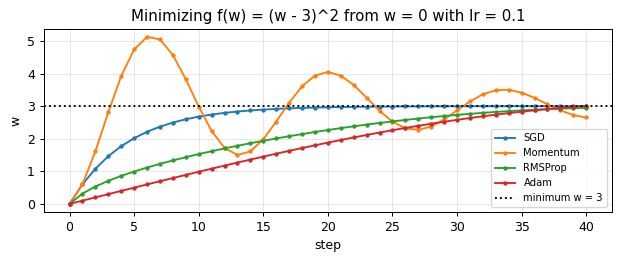

skipped: needs torch


In [20]:
grad = lambda w: 2 * (w - 3)


def run_optimizer(kind, w0=0.0, lr=0.1, steps=3, beta=0.9, rho=0.9, b1=0.9, b2=0.999, eps=1e-8):
    w, v, s, m, path = w0, 0.0, 0.0, 0.0, [w0]
    for t in range(1, steps + 1):
        g = grad(w)
        if kind == "SGD":
            w = w - lr * g
        elif kind == "Momentum":
            v = beta * v + g
            w = w - lr * v
        elif kind == "RMSProp":
            s = rho * s + (1 - rho) * g**2
            w = w - lr * g / (np.sqrt(s) + eps)
        elif kind == "Adam":
            m = b1 * m + (1 - b1) * g
            v = b2 * v + (1 - b2) * g**2
            m_hat, v_hat = m / (1 - b1**t), v / (1 - b2**t)
            w = w - lr * m_hat / (np.sqrt(v_hat) + eps)
        path.append(w)
    return np.array(path)


hand_table = {"SGD": [0.6, 1.08, 1.464], "Momentum": [0.6, 1.62, 2.814],
              "RMSProp": [0.3162, 0.5332, 0.7082], "Adam": [0.1, 0.1999, 0.2996]}
for kind, hand in hand_table.items():
    check(f"{kind}: w1, w2, w3", run_optimizer(kind)[1:], hand)
check("Momentum: step 4 overshoots", run_optimizer("Momentum", steps=4)[-1], 3.9258)

# Intermediate values of the hand solution
check("RMSProp step 1: s, sqrt(s)", [0.1 * 36, np.sqrt(3.6)], [3.6, 1.8974])
g2 = grad(run_optimizer("RMSProp", steps=1)[-1])
s2 = 0.9 * 3.6 + 0.1 * g2**2
check("RMSProp step 2: g, g^2, s, sqrt(s)", [g2, g2**2, s2, np.sqrt(s2)], [-5.3675, 28.8105, 6.1211, 2.4741])
check("Adam step 2: m, v", [0.9 * -0.6 + 0.1 * -5.8, 0.999 * 0.036 + 0.001 * 5.8**2], [-1.12, 0.069604], atol=1e-6)
check("Adam step 2: m_hat, v_hat", [-1.12 / 0.19, 0.069604 / (1 - 0.999**2)], [-5.8947, 34.8194])

# Figure: 40 steps of each optimizer
fig, ax = plt.subplots(figsize=(7, 3))
for kind in hand_table:
    ax.plot(run_optimizer(kind, steps=40), marker="o", markersize=2.5, label=kind)
ax.axhline(3, color="black", linestyle=":", label="minimum w = 3")
ax.set_xlabel("step"); ax.set_ylabel("w"); ax.set_title("Minimizing f(w) = (w - 3)^2 from w = 0 with lr = 0.1")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

try:
    import torch

    def torch_path(make_opt, steps=3):
        w_t = torch.zeros(1, dtype=torch.float64, requires_grad=True)
        opt = make_opt([w_t])
        out = []
        for _ in range(steps):
            opt.zero_grad()
            ((w_t - 3) ** 2).sum().backward()
            opt.step()
            out.append(w_t.item())
        return out

    check("torch SGD", torch_path(lambda p: torch.optim.SGD(p, lr=0.1)), hand_table["SGD"])
    check("torch SGD momentum", torch_path(lambda p: torch.optim.SGD(p, lr=0.1, momentum=0.9)), hand_table["Momentum"])
    check("torch RMSprop", torch_path(lambda p: torch.optim.RMSprop(p, lr=0.1, alpha=0.9, eps=1e-8)), hand_table["RMSProp"])
    check("torch Adam", torch_path(lambda p: torch.optim.Adam(p, lr=0.1, betas=(0.9, 0.999), eps=1e-8)), hand_table["Adam"])
except ImportError:
    print("skipped: needs torch")

### Try it yourself

Same $f(w) = (w - 3)^2$ and settings, but start at $w_0 = 1$. Do two steps of SGD, momentum, RMSProp and Adam.

<details><summary>Answer</summary>

SGD: $g = -4$, $w_1 = 1.4$; $g = -3.2$, $w_2 = 1.72$.
Momentum: $v = -4$, $w_1 = 1.4$; $v = 0.9\cdot(-4) - 3.2 = -6.8$, $w_2 = 2.08$.
RMSProp: $s = 1.6$, $w_1 = 1 + 0.1\cdot4/1.2649 = 1.3162$; then $g = -3.3675$, $s = 2.5740$, $w_2 = 1.5261$.
Adam: $w_1 = 1.1$ (the first Adam step always has length $\eta$); then $m = -0.74$, $v = 0.030424$, $\hat m = -3.8947$, $\hat v = 15.2196$, $w_2 = 1.1998$.

</details>

**Common mistake:** dropping Adam's bias correction. At $t = 1$, $m = -0.6$ and $\sqrt{v} = 0.1897$ are both too small, but not by the same factor: their ratio is off by $(1-\beta_1)/\sqrt{1-\beta_2} = 0.1/0.0316 = 3.16$, so the first steps would be about 3 times too large.

## 20. Learning rate: too small, good, too large

**What it is.** The learning rate $\eta$ sets the step size. On our quadratic the effect can be worked out exactly:

$$w_{t+1} = w_t - \eta\cdot2(w_t - 3) \quad\Longrightarrow\quad w_{t+1} - 3 = (1 - 2\eta)\,(w_t - 3)$$

Each step multiplies the distance to the minimum by $r = 1 - 2\eta$. Training converges only if $|r| < 1$, that is $0 < \eta < 1$. If $r < 0$ the weight jumps from side to side.

**Everyday analogy.** Tuning a guitar string: turn the peg a tiny bit and it takes forever; turn it far too much and you overshoot further and further from the right note.

### Problem

$f(w) = (w - 3)^2$, plain gradient descent from $w_0 = 0$. Do 3 steps with $\eta = 0.01$, $\eta = 0.4$, $\eta = 0.9$ and $\eta = 1.1$. What happens with $\eta = 0.5$ and $\eta = 1.0$?

### Solution by hand

The starting distance is $w_0 - 3 = -3$, so $w_t = 3 + r^t\cdot(-3)$.

| $\eta$ | $r = 1 - 2\eta$ | $w_1$ | $w_2$ | $w_3$ | verdict |
|---|---|---|---|---|---|
| 0.01 | 0.98 | 0.06 | 0.1188 | 0.1764 | too small: crawling |
| 0.4 | 0.2 | 2.4 | 2.88 | 2.976 | good: fast |
| 0.9 | -0.8 | 5.4 | 1.08 | 4.536 | zig-zags, but converges slowly |
| 1.1 | -1.2 | 6.6 | -1.32 | 8.184 | too large: **diverges** |

Example for $\eta = 1.1$: $w_1 = 3 + (-1.2)(-3) = 6.6$; $\;w_2 = 3 + (-1.2)(3.6) = -1.32$; $\;w_3 = 3 + (-1.2)(-4.32) = 8.184$. The losses $f(w)$ are $12.96, 18.6624, 26.8739$: going **up**.

Special cases: $\eta = 0.5$ gives $r = 0$, so $w_1 = 3$ exactly (one step); $\eta = 1.0$ gives $r = -1$, so $w$ bounces $0, 6, 0, 6, \dots$ forever.

lr = 0.01: w1, w2, w3              numpy = [0.0600, 0.1188, 0.1764] hand = [0.0600, 0.1188, 0.1764] OK
lr = 0.4: w1, w2, w3               numpy = [2.4000, 2.8800, 2.9760] hand = [2.4000, 2.8800, 2.9760] OK
lr = 0.9: w1, w2, w3               numpy = [5.4000, 1.0800, 4.5360] hand = [5.4000, 1.0800, 4.5360] OK
lr = 1.1: w1, w2, w3               numpy = [6.6000, -1.3200, 8.1840] hand = [6.6000, -1.3200, 8.1840] OK
lr = 1.1: losses f(w1..w3)         numpy = [12.9600, 18.6624, 26.8739] hand = [12.9600, 18.6624, 26.8739] OK
lr = 0.5: one step                 numpy = 3.0000                   hand = 3.0000                   OK
lr = 1.0: bounces                  numpy = [0.0000, 6.0000, 0.0000, 6.0000, 0.0000] hand = [0.0000, 6.0000, 0.0000, 6.0000, 0.0000] OK


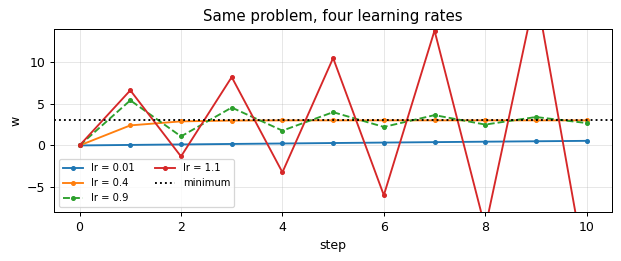

In [21]:
def gd_path(lr, steps, w0=0.0):
    path = [w0]
    for _ in range(steps):
        path.append(path[-1] - lr * 2 * (path[-1] - 3))
    return np.array(path)


hand = {0.01: [0.06, 0.1188, 0.1764], 0.4: [2.4, 2.88, 2.976], 0.9: [5.4, 1.08, 4.536], 1.1: [6.6, -1.32, 8.184]}
for lr, values in hand.items():
    check(f"lr = {lr}: w1, w2, w3", gd_path(lr, 3)[1:], values)
check("lr = 1.1: losses f(w1..w3)", (gd_path(1.1, 3)[1:] - 3) ** 2, [12.96, 18.6624, 26.8739])
check("lr = 0.5: one step", gd_path(0.5, 1)[1], 3.0)
check("lr = 1.0: bounces", gd_path(1.0, 4), [0, 6, 0, 6, 0])

fig, ax = plt.subplots(figsize=(7, 3))
for lr, style in [(0.01, "-"), (0.4, "-"), (0.9, "--"), (1.1, "-")]:
    ax.plot(gd_path(lr, 10), style, marker="o", markersize=3, label=f"lr = {lr}")
ax.axhline(3, color="black", linestyle=":", label="minimum")
ax.set_ylim(-8, 14); ax.set_xlabel("step"); ax.set_ylabel("w")
ax.set_title("Same problem, four learning rates")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

### Try it yourself

$f(w) = 2(w - 1)^2$, so $g = 4(w - 1)$. Start at $w_0 = 3$. (a) Do 3 steps with $\eta = 0.1$. (b) For which $\eta$ does gradient descent converge? (c) What happens with $\eta = 0.6$?

<details><summary>Answer</summary>

Here $w_{t+1} - 1 = (1 - 4\eta)(w_t - 1)$.
(a) $r = 0.6$: $w = 1 + 2\cdot0.6 = 2.2$, then $1.72$, then $1.432$.
(b) $|1 - 4\eta| < 1$, so $0 < \eta < 0.5$.
(c) $r = -1.4$: $w = -1.8,\ 4.92,\ -4.488$: it diverges.

</details>

**Exam tip:** for a quadratic whose second derivative (curvature) is $L$, gradient descent converges if and only if $0 < \eta < 2/L$. Here $f'' = 2$, so $\eta < 1$; in the practice problem $f'' = 4$, so $\eta < 0.5$.

## 21. Learning-rate decay and schedules

**What it is.** Big steps help early (to travel fast); small steps help late (to settle into the minimum instead of bouncing around it). A **schedule** lowers the learning rate over time. Common formulas, with starting rate $\alpha_0$:

| Schedule | Formula |
|---|---|
| $1/t$ ("inverse time") decay | $\alpha = \dfrac{\alpha_0}{1 + k\cdot\text{epoch}}$, where $k$ is the `decay_rate` |
| Exponential decay | $\alpha = 0.95^{\text{epoch}}\cdot\alpha_0$ (any base below 1) |
| Step decay | $\alpha = \alpha_0\cdot\gamma^{\lfloor \text{epoch}/s\rfloor}$, for example halve ($\gamma = 0.5$) every $s = 2$ epochs |
| Linear warmup, then cosine | $\alpha_t = \alpha_{\max}\cdot\dfrac{t}{W}$ for $t < W$; then $\alpha_t = \tfrac12\alpha_{\max}\big(1 + \cos(\pi p)\big)$ with progress $p = \dfrac{t - W}{T - W}$ |

**Warmup** starts with tiny steps while the optimizer statistics (for example Adam's $v$) are still unreliable; **cosine** then glides smoothly down to (nearly) zero at the last step $T$. This combination is standard for training Transformers.

**Everyday analogy.** Parking a car: accelerate gently out of the space (warmup), drive at speed, then slow down more and more as you approach the target spot.

### Problem

(a)-(c) With $\alpha_0 = 0.2$, compute the learning rate for epochs 0-4 under $1/t$ decay with `decay_rate` $k = 1$, exponential decay with base $0.95$, and step decay that halves every 2 epochs.
(d) Warmup + cosine with $\alpha_{\max} = 0.1$, warmup $W = 10$ steps, total $T = 110$ steps (minimum 0): compute $\alpha_t$ at $t = 0, 5, 10, 35, 60, 85, 110$.

### Solution by hand

**(a)-(c)**

| epoch | $1/t$: $0.2/(1 + \text{epoch})$ | exponential: $0.95^{\text{epoch}}\cdot0.2$ | step: $0.2\cdot0.5^{\lfloor \text{epoch}/2\rfloor}$ |
|---|---|---|---|
| 0 | $0.2/1 = 0.2$ | $0.2$ | $0.2$ |
| 1 | $0.2/2 = 0.1$ | $0.95\cdot0.2 = 0.19$ | $0.2$ |
| 2 | $0.2/3 = 0.0667$ | $0.9025\cdot0.2 = 0.1805$ | $0.1$ |
| 3 | $0.2/4 = 0.05$ | $0.857375\cdot0.2 = 0.1715$ | $0.1$ |
| 4 | $0.2/5 = 0.04$ | $0.81450625\cdot0.2 = 0.1629$ | $0.05$ |

**(d)**
1. Warmup ($t < 10$): $\alpha_0 = 0.1\cdot0/10 = 0$; $\;\alpha_5 = 0.1\cdot5/10 = 0.05$.
2. $t = 10$: $p = 0$, $\cos 0 = 1$, so $\alpha = \tfrac12\cdot0.1\cdot2 = 0.1$ (the peak).
3. $t = 35$: $p = 25/100 = 0.25$, $\cos(\pi/4) = 0.7071$, so $\alpha = 0.05\cdot1.7071 = 0.0854$.
4. $t = 60$: $p = 0.5$, $\cos(\pi/2) = 0$, so $\alpha = 0.05$.
5. $t = 85$: $p = 0.75$, $\cos(3\pi/4) = -0.7071$, so $\alpha = 0.05\cdot0.2929 = 0.0146$.
6. $t = 110$: $p = 1$, $\cos\pi = -1$, so $\alpha = 0$.

1/t decay                          numpy = [0.2000, 0.1000, 0.0667, 0.0500, 0.0400] hand = [0.2000, 0.1000, 0.0667, 0.0500, 0.0400] OK
exponential decay                  numpy = [0.2000, 0.1900, 0.1805, 0.1715, 0.1629] hand = [0.2000, 0.1900, 0.1805, 0.1715, 0.1629] OK
step decay                         numpy = [0.2000, 0.2000, 0.1000, 0.1000, 0.0500] hand = [0.2000, 0.2000, 0.1000, 0.1000, 0.0500] OK
warmup + cosine                    numpy = [0.0000, 0.0500, 0.1000, 0.0854, 0.0500, 0.0146, 0.0000] hand = [0.0000, 0.0500, 0.1000, 0.0854, 0.0500, 0.0146, 0.0000] OK


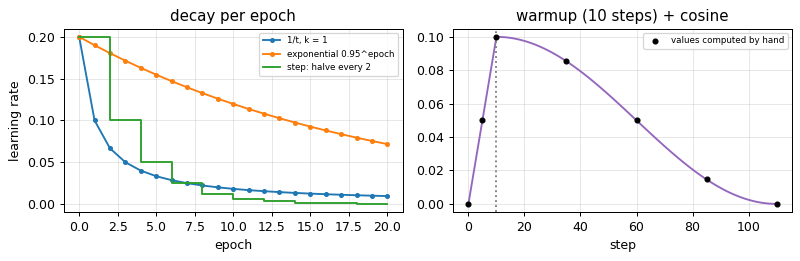

In [22]:
alpha0 = 0.2
epochs = np.arange(5)
inv_time = alpha0 / (1 + 1.0 * epochs)
exponential = 0.95**epochs * alpha0
step = alpha0 * 0.5 ** (epochs // 2)
check("1/t decay", inv_time, [0.2, 0.1, 0.0667, 0.05, 0.04])
check("exponential decay", exponential, [0.2, 0.19, 0.1805, 0.1715, 0.1629])
check("step decay", step, [0.2, 0.2, 0.1, 0.1, 0.05])


def warmup_cosine(t, peak=0.1, warmup=10, total=110, lr_min=0.0):
    if t < warmup:
        return peak * t / warmup
    progress = (t - warmup) / (total - warmup)
    return lr_min + 0.5 * (peak - lr_min) * (1 + math.cos(math.pi * progress))


ts = [0, 5, 10, 35, 60, 85, 110]
check("warmup + cosine", [warmup_cosine(t) for t in ts], [0.0, 0.05, 0.1, 0.0854, 0.05, 0.0146, 0.0])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3))
e = np.arange(21)
ax1.plot(e, alpha0 / (1 + e), marker=".", label="1/t, k = 1")
ax1.plot(e, 0.95**e * alpha0, marker=".", label="exponential 0.95^epoch")
ax1.step(e, alpha0 * 0.5 ** (e // 2), where="post", label="step: halve every 2")
ax1.set_xlabel("epoch"); ax1.set_ylabel("learning rate"); ax1.set_title("decay per epoch"); ax1.legend(fontsize=7)
t_all = np.arange(111)
ax2.plot(t_all, [warmup_cosine(t) for t in t_all], color="tab:purple")
ax2.scatter(ts, [warmup_cosine(t) for t in ts], color="black", zorder=3, s=15, label="values computed by hand")
ax2.axvline(10, color="gray", linestyle=":")
ax2.set_xlabel("step"); ax2.set_title("warmup (10 steps) + cosine"); ax2.legend(fontsize=7)
plt.tight_layout()
plt.show()

### Try it yourself

(a) $\alpha_0 = 0.1$ with $1/t$ decay, `decay_rate` $k = 0.5$: the rate at epochs 1, 2, 3. (b) Exponential decay with base $0.9$: epochs 1, 2, 3. (c) Warmup + cosine with $\alpha_{\max} = 0.05$, $W = 5$, $T = 45$: the rate at $t = 2, 15, 25, 35$.

<details><summary>Answer</summary>

(a) $0.1/1.5 = 0.0667$, $\;0.1/2 = 0.05$, $\;0.1/2.5 = 0.04$.
(b) $0.09$, $0.081$, $0.0729$.
(c) $t = 2$: warmup, $0.05\cdot2/5 = 0.02$. $t = 15$: $p = 10/40 = 0.25$, $0.025\cdot1.7071 = 0.0427$. $t = 25$: $p = 0.5$, $0.025$. $t = 35$: $p = 0.75$, $0.025\cdot0.2929 = 0.0073$.

</details>

**Exam tip:** at the halfway point of a cosine schedule (with minimum 0) the rate is always exactly half the peak.

## 22. Hyperparameter search on a log scale

**What it is.** Hyperparameters such as the learning rate can sensibly be anywhere from $0.0001$ to $1$. Sampling that range **uniformly** wastes almost every trial on the largest values. Instead, sample the **exponent** uniformly: $r \sim U[-4, 0]$, $\alpha = 10^r$. Then each factor-of-10 range ("decade") gets the same number of trials. For momentum-like $\beta$ close to 1, sample $1 - \beta$ on a log scale instead.

**Everyday analogy.** Looking for the right amount of salt: trying 1 g, 10 g and 100 g tells you far more than trying 91 g, 94 g and 97 g.

### Problem

(a) If $\alpha$ is sampled uniformly from $[0.0001, 1]$, what fraction of the samples lands in $[0.1, 1]$?
(b) On a log scale, convert the draws $r = -3.2, -1.5, -0.7$ into learning rates.
(c) $\beta \in [0.9, 0.999]$: sample $r \sim U[-3, -1]$ and set $\beta = 1 - 10^r$. Convert $r = -1, -2, -2.5, -3$ and give the averaging window $1/(1-\beta)$ of each.

### Solution by hand

1. **(a)** $\dfrac{1 - 0.1}{1 - 0.0001} = \dfrac{0.9}{0.9999} = 0.9001$: about 90% of the trials test values between $0.1$ and $1$; the three decades below share only 10%.
2. **(b)** $10^{-3.2} = 6.3096\times10^{-4}$, $\;10^{-1.5} = 0.0316$, $\;10^{-0.7} = 0.1995$. With $r \sim U[-4, 0]$, each decade $[10^{-4}, 10^{-3}], \dots, [10^{-1}, 1]$ gets 25% of the trials.
3. **(c)**

| $r$ | $1 - \beta = 10^r$ | $\beta$ | window $1/(1-\beta)$ |
|---|---|---|---|
| -1 | 0.1 | 0.9 | 10 |
| -2 | 0.01 | 0.99 | 100 |
| -2.5 | 0.0032 | 0.9968 | 316.2278 |
| -3 | 0.001 | 0.999 | 1000 |

Why: near 1, tiny changes in $\beta$ matter enormously. Going from $0.9$ to $0.9005$ changes the window from 10 to $10.05$; going from $0.999$ to $0.9995$ doubles it from 1000 to 2000.

In [23]:
check("(a) uniform: fraction in [0.1, 1]", (1 - 0.1) / (1 - 0.0001), 0.9001)
check("(b) 10^r", [10**-3.2, 10**-1.5, 10**-0.7], [6.3096e-4, 0.0316, 0.1995])
r_beta = np.array([-1.0, -2.0, -2.5, -3.0])
beta = 1 - 10**r_beta
check("(c) beta = 1 - 10^r", beta, [0.9, 0.99, 0.9968, 0.999])
check("(c) window 1/(1-beta)", 1 / (1 - beta), [10.0, 100.0, 316.2278, 1000.0])
check("window for beta = 0.9005 and 0.9995", [1 / (1 - 0.9005), 1 / (1 - 0.9995)], [10.0503, 2000.0])

# Simulate 100,000 draws both ways and count how many land in each decade
n = 100_000
uniform = rng.uniform(1e-4, 1, n)
log_scale = 10 ** rng.uniform(-4, 0, n)
edges = [1e-4, 1e-3, 1e-2, 1e-1, 1]
frac_uniform = np.histogram(uniform, bins=edges)[0] / n
frac_log = np.histogram(log_scale, bins=edges)[0] / n
print("fraction per decade [1e-4,1e-3], [1e-3,1e-2], [1e-2,1e-1], [1e-1,1]")
print("  uniform sampling:  ", fmt(frac_uniform))
print("  log-scale sampling:", fmt(frac_log))
check("uniform: share of top decade", frac_uniform[-1], 0.9001, atol=0.005)
check("log scale: every decade", frac_log, [0.25, 0.25, 0.25, 0.25], atol=0.005)

(a) uniform: fraction in [0.1, 1]  numpy = 0.9001                   hand = 0.9001                   OK
(b) 10^r                           numpy = [6.3096e-04, 0.0316, 0.1995] hand = [6.3096e-04, 0.0316, 0.1995] OK
(c) beta = 1 - 10^r                numpy = [0.9000, 0.9900, 0.9968, 0.9990] hand = [0.9000, 0.9900, 0.9968, 0.9990] OK
(c) window 1/(1-beta)              numpy = [10.0000, 100.0000, 316.2278, 1000.0000] hand = [10.0000, 100.0000, 316.2278, 1000.0000] OK
window for beta = 0.9005 and 0.9995 numpy = [10.0503, 2000.0000]     hand = [10.0503, 2000.0000]     OK
fraction per decade [1e-4,1e-3], [1e-3,1e-2], [1e-2,1e-1], [1e-1,1]
  uniform sampling:   [7.0000e-04, 0.0094, 0.0897, 0.9002]
  log-scale sampling: [0.2467, 0.2542, 0.2493, 0.2498]
uniform: share of top decade       numpy = 0.9002                   hand = 0.9001                   OK
log scale: every decade            numpy = [0.2467, 0.2542, 0.2493, 0.2498] hand = [0.2500, 0.2500, 0.2500, 0.2500] OK


### Try it yourself

(a) You want learning rates between $10^{-5}$ and $10^{-2}$ on a log scale. What range should $r$ come from, and what is $\alpha$ for $r = -3.5$? (b) Convert $r = -1.5$ into $\beta = 1 - 10^r$ and give its averaging window.

<details><summary>Answer</summary>

(a) $r \sim U[-5, -2]$; $\alpha = 10^{-3.5} = 3.1623\times10^{-4}$.
(b) $\beta = 1 - 0.0316 = 0.9684$; window $= 1/0.0316 = 31.6228$.

</details>

**Exam tip:** prefer **random search** to a grid: with a $5\times5$ grid you only ever try 5 distinct values of each hyperparameter, while 25 random trials try 25 distinct values of each. Then zoom in ("coarse to fine") around the best region.

## 23. Train / dev / test split sizes

**What it is.** The **training set** fits the weights, the **dev set** (also called the validation set) is used to compare models and tune hyperparameters, and the **test set** gives a final, unbiased estimate. With small datasets a classic split is 60/20/20. With a million examples, 1% is already a big dev set, so splits like 98/1/1 are common: the dev and test sets only need to be large enough to tell good models apart. (Dev and test must come from the same distribution: the data you will meet in real use.)

How large is "large enough"? For an accuracy $p$ measured on $n$ examples, the standard error is $\sqrt{p(1-p)/n}$, and a 95% interval is about $\pm1.96$ standard errors.

**Everyday analogy.** To check whether a big pot of soup is salty enough you need one spoonful, not one bowl in five.

### Problem

(a) Split 10,000 examples 60/20/20. (b) Split 1,000,000 examples 98/1/1. (c) For a model with accuracy $p = 0.95$, compute the 95% interval half-width on a dev set of $n = 10{,}000$ (the 1% dev set) and on $n = 2{,}000$ (the 20% dev set of the small dataset).

### Solution by hand

1. **(a)** $0.6\cdot10000 = 6{,}000$ train, $2{,}000$ dev, $2{,}000$ test.
2. **(b)** $980{,}000$ train, $10{,}000$ dev, $10{,}000$ test.
3. **(c)** $n = 10{,}000$: standard error $= \sqrt{0.95\cdot0.05/10000} = \sqrt{4.75\times10^{-6}} = 0.0022$ (that is $0.2179\%$); half-width $= 1.96\cdot0.2179\% = 0.4272\%$. So 10,000 dev examples measure accuracy to within about $\pm0.43$ percentage points.
4. $n = 2{,}000$: standard error $= \sqrt{0.0475/2000} = 0.0049$ (that is $0.4873\%$); half-width $= 0.9552\%$, about $\pm1$ point.

A 20% dev set of the million-example dataset (200,000 examples) would give $\pm0.0955$ points: more precision than needed, bought with 190,000 examples taken away from training.

In [24]:
check("(a) 60/20/20 of 10,000", np.array([0.6, 0.2, 0.2]) * 10_000, [6000, 2000, 2000])
check("(b) 98/1/1 of 1,000,000", np.array([0.98, 0.01, 0.01]) * 1_000_000, [980_000, 10_000, 10_000])


def half_width_pct(p, n):
    return 100 * 1.96 * math.sqrt(p * (1 - p) / n)


check("(c) standard error n=10,000 (%)", 100 * math.sqrt(0.95 * 0.05 / 10_000), 0.2179)
check("(c) half-width n=10,000 (%)", half_width_pct(0.95, 10_000), 0.4272)
check("(c) standard error n=2,000 (%)", 100 * math.sqrt(0.95 * 0.05 / 2_000), 0.4873)
check("(c) half-width n=2,000 (%)", half_width_pct(0.95, 2_000), 0.9552)
check("half-width n=200,000 (%)", half_width_pct(0.95, 200_000), 0.0955)

(a) 60/20/20 of 10,000             numpy = [6000.0000, 2000.0000, 2000.0000] hand = [6000.0000, 2000.0000, 2000.0000] OK
(b) 98/1/1 of 1,000,000            numpy = [980000.0000, 10000.0000, 10000.0000] hand = [980000.0000, 10000.0000, 10000.0000] OK
(c) standard error n=10,000 (%)    numpy = 0.2179                   hand = 0.2179                   OK
(c) half-width n=10,000 (%)        numpy = 0.4272                   hand = 0.4272                   OK
(c) standard error n=2,000 (%)     numpy = 0.4873                   hand = 0.4873                   OK
(c) half-width n=2,000 (%)         numpy = 0.9552                   hand = 0.9552                   OK
half-width n=200,000 (%)           numpy = 0.0955                   hand = 0.0955                   OK


### Try it yourself

You have 50,000 examples and choose a 90/5/5 split. How many examples are in each part? If the model's dev accuracy is $p = 0.9$, what is the 95% half-width?

<details><summary>Answer</summary>

$45{,}000 / 2{,}500 / 2{,}500$. Standard error $= \sqrt{0.9\cdot0.1/2500} = \sqrt{0.000036} = 0.006$; half-width $= 1.96\cdot0.6\% = 1.176\%$, so about $\pm1.2$ points.

</details>

**Common mistake:** making the dev set from a different source than the test set (for example dev from web images, test from phone photos). You would be tuning towards the wrong target.

## 24. Single-number metric, optimizing and satisficing metrics

**What it is.**
- With two metrics (precision $P$ and recall $R$) it is hard to rank models. A **single-number evaluation metric** such as $F_1 = \dfrac{2PR}{P + R}$ (the harmonic mean) makes the choice quick. The harmonic mean is pulled down by the smaller of the two numbers, so it punishes a model that is bad at either. (Precision, recall and F1 from a confusion matrix are worked out in the [ML numericals notebook](../03_Machine_Learning/00c_ml_numericals_solved_by_hand.ipynb).)
- When several things matter, pick one **optimizing** metric (make it as good as possible) and turn the others into **satisficing** metrics (they only need to pass a threshold, such as "runtime at most 100 ms").

**Everyday analogy.** Buying a flat: you want the most space (optimizing), as long as the rent is at most your budget and the commute at most 30 minutes (satisficing). A flat with a shorter commute than needed earns no extra points.

### Problem

(a) Three classifiers on the same dev set:

| model | precision $P$ | recall $R$ |
|---|---|---|
| A | 0.92 | 0.80 |
| B | 0.85 | 0.88 |
| C | 0.99 | 0.75 |

Compute the plain average $(P+R)/2$ and $F_1$ for each. Which model does each rule pick?

(b) Choose the model with the best accuracy among those whose runtime is at most 100 ms:

| model | dev accuracy | runtime per example |
|---|---|---|
| M1 | 91.0% | 40 ms |
| M2 | 94.0% | 85 ms |
| M3 | 96.5% | 150 ms |
| M4 | 93.2% | 60 ms |

### Solution by hand

**(a)**
1. A: average $= 0.86$; $\;F_1 = \dfrac{2\cdot0.92\cdot0.80}{0.92 + 0.80} = \dfrac{1.472}{1.72} = 0.8558$
2. B: average $= 0.865$; $\;F_1 = \dfrac{2\cdot0.85\cdot0.88}{1.73} = \dfrac{1.496}{1.73} = 0.8647$
3. C: average $= 0.87$; $\;F_1 = \dfrac{2\cdot0.99\cdot0.75}{1.74} = \dfrac{1.485}{1.74} = 0.8534$
4. The plain average picks **C**, but $F_1$ picks **B**: C's excellent precision hides a weak recall (it misses a quarter of the positives), and the harmonic mean does not let one strong number make up for a weak one.

**(b)**
5. Satisficing check (runtime $\le 100$ ms): M1, M2 and M4 pass; M3 (150 ms) is out, however accurate it is.
6. Optimizing metric among the rest: the highest accuracy is **M2** (94.0%).

In [25]:
models = {"A": (0.92, 0.80), "B": (0.85, 0.88), "C": (0.99, 0.75)}
avg = {k: (P + R) / 2 for k, (P, R) in models.items()}
f1 = {k: 2 * P * R / (P + R) for k, (P, R) in models.items()}
check("plain averages A, B, C", list(avg.values()), [0.86, 0.865, 0.87])
check("F1 for A, B, C", list(f1.values()), [0.8558, 0.8647, 0.8534])
best_avg, best_f1 = max(avg, key=avg.get), max(f1, key=f1.get)
print("plain average picks", best_avg, "| F1 picks", best_f1)
assert (best_avg, best_f1) == ("C", "B")

table = {"M1": (91.0, 40), "M2": (94.0, 85), "M3": (96.5, 150), "M4": (93.2, 60)}
feasible = {k: acc for k, (acc, ms) in table.items() if ms <= 100}
chosen = max(feasible, key=feasible.get)
print("models meeting the runtime limit:", list(feasible), "-> chosen:", chosen)
assert chosen == "M2"

plain averages A, B, C             numpy = [0.8600, 0.8650, 0.8700] hand = [0.8600, 0.8650, 0.8700] OK
F1 for A, B, C                     numpy = [0.8558, 0.8647, 0.8534] hand = [0.8558, 0.8647, 0.8534] OK
plain average picks C | F1 picks B
models meeting the runtime limit: ['M1', 'M2', 'M4'] -> chosen: M2


### Try it yourself

(a) Model X has $P = 0.90$, $R = 0.60$; model Y has $P = 0.75$, $R = 0.78$. Compute both $F_1$ scores.
(b) Pick the most accurate model with latency at most 50 ms **and** size at most 50 MB: P1 (88%, 30 ms, 20 MB), P2 (92%, 45 ms, 80 MB), P3 (90%, 48 ms, 35 MB), P4 (95%, 120 ms, 40 MB).

<details><summary>Answer</summary>

(a) $F_1(X) = 2\cdot0.9\cdot0.6/1.5 = 1.08/1.5 = 0.72$; $\;F_1(Y) = 2\cdot0.75\cdot0.78/1.53 = 1.17/1.53 = 0.7647$. Y is better.
(b) P2 fails the size limit and P4 the latency limit. Of P1 and P3, **P3** (90%) is more accurate.

</details>

**Exam tip:** with $N$ metrics, choose 1 optimizing and $N - 1$ satisficing metrics. Combining unrelated metrics into one weighted formula (such as "accuracy minus 0.5 times runtime") is possible, but the weights are arbitrary.

## 25. Human-level error, avoidable bias, variance and data mismatch

**What it is.** Compare error rates to decide what to work on next:
- **Bayes error** is the lowest error any model could reach (some examples are simply ambiguous). For tasks people are good at, the best **human-level error** is a good stand-in (an upper bound) for it.
- **Avoidable bias** $=$ training error $-$ human-level error. If large: use a bigger model, train longer, try a better architecture or optimizer.
- **Variance** $=$ dev error $-$ training error. If large: get more data, add regularization (L2, dropout, augmentation).
- When training data comes from a different source than dev/test data, hold out a **train-dev** set (same distribution as training, never trained on). Then variance $=$ train-dev $-$ train, and **data mismatch** $=$ dev $-$ train-dev. If large: collect or synthesize training data that looks like the dev data.
- Test $-$ dev measures **overfitting to the dev set** (fix: a bigger dev set).

**Everyday analogy.** A student who gets 70% on practice questions has a *learning* problem (bias); one who gets 98% on practice but 70% on the exam has a *memorizing* problem (variance); one who practised with questions from a different syllabus has a *mismatch* problem.

### Problem

(a) Reading handwritten postcodes: an untrained person makes 2.5% errors, a trained clerk 1.2%, a team of trained clerks 0.7%. Your model has 1.5% training error and 1.9% dev error. Which human level should stand in for Bayes error? Is bias or variance the bigger problem? What would you wrongly conclude if you used 2.5%?

(b) Human-level error is 1.0% in both scenarios. Which problem dominates?

| scenario | train error | dev error |
|---|---|---|
| S1 | 6.0% | 7.5% |
| S2 | 1.8% | 6.0% |

(c) Human-level 1.0%, train 2.0%, train-dev 2.5%, dev 8.0%, test 8.4%. Compute every gap.

### Solution by hand

**(a)**
1. Bayes error is at most the *best* human performance, so use $0.7\%$.
2. Avoidable bias $= 1.5 - 0.7 = 0.8$ points; variance $= 1.9 - 1.5 = 0.4$ points. Bias is bigger: work on fitting the training set better.
3. With 2.5% you would get avoidable bias $= 1.5 - 2.5 = -1.0$ and think the model is "better than human, no bias left", and wrongly spend your time on variance.

**(b)**
4. S1: avoidable bias $= 6.0 - 1.0 = 5.0$, variance $= 7.5 - 6.0 = 1.5$: **bias** dominates.
5. S2: avoidable bias $= 1.8 - 1.0 = 0.8$, variance $= 6.0 - 1.8 = 4.2$: **variance** dominates.

**(c)**

| gap | computation | size |
|---|---|---|
| avoidable bias | train $-$ human $= 2.0 - 1.0$ | 1.0 |
| variance | train-dev $-$ train $= 2.5 - 2.0$ | 0.5 |
| data mismatch | dev $-$ train-dev $= 8.0 - 2.5$ | **5.5** |
| overfitting to dev | test $-$ dev $= 8.4 - 8.0$ | 0.4 |

6. Data mismatch is by far the largest: the model works on data like its training data but not on the real (dev) data. Collect or synthesize training examples that resemble the dev set.

In [26]:
human_levels = {"untrained person": 0.025, "trained clerk": 0.012, "team of clerks": 0.007}
bayes_proxy = min(human_levels.values())
train_err, dev_err = 0.015, 0.019
check("(a) Bayes proxy (%)", 100 * bayes_proxy, 0.7)
check("(a) avoidable bias, variance (pts)", [100 * (train_err - bayes_proxy), 100 * (dev_err - train_err)], [0.8, 0.4])
check("(a) bias with the wrong 2.5% (pts)", 100 * (train_err - 0.025), -1.0)


def diagnose(human, train, dev):
    bias, var = train - human, dev - train
    return bias, var, "bias" if bias > var else "variance"


for name, (tr, dv), expected in [("S1", (6.0, 7.5), (5.0, 1.5)), ("S2", (1.8, 6.0), (0.8, 4.2))]:
    bias, var, worst = diagnose(1.0, tr, dv)
    check(f"(b) {name}: avoidable bias, variance", [bias, var], expected)
    print(f"     {name}: work on {worst}")

errors = {"human": 1.0, "train": 2.0, "train-dev": 2.5, "dev": 8.0, "test": 8.4}
gaps = {
    "avoidable bias": errors["train"] - errors["human"],
    "variance": errors["train-dev"] - errors["train"],
    "data mismatch": errors["dev"] - errors["train-dev"],
    "overfitting to dev": errors["test"] - errors["dev"],
}
check("(c) gaps", list(gaps.values()), [1.0, 0.5, 5.5, 0.4])
biggest = max(gaps, key=gaps.get)
print("(c) biggest gap:", biggest)
assert biggest == "data mismatch"

(a) Bayes proxy (%)                numpy = 0.7000                   hand = 0.7000                   OK
(a) avoidable bias, variance (pts) numpy = [0.8000, 0.4000]         hand = [0.8000, 0.4000]         OK
(a) bias with the wrong 2.5% (pts) numpy = -1.0000                  hand = -1.0000                  OK
(b) S1: avoidable bias, variance   numpy = [5.0000, 1.5000]         hand = [5.0000, 1.5000]         OK
     S1: work on bias
(b) S2: avoidable bias, variance   numpy = [0.8000, 4.2000]         hand = [0.8000, 4.2000]         OK
     S2: work on variance
(c) gaps                           numpy = [1.0000, 0.5000, 5.5000, 0.4000] hand = [1.0000, 0.5000, 5.5000, 0.4000] OK
(c) biggest gap: data mismatch


### Try it yourself

Human-level error 0.5%, training 0.9%, train-dev 3.9%, dev 4.4%. Compute avoidable bias, variance and data mismatch. What should you work on first?

<details><summary>Answer</summary>

Avoidable bias $= 0.9 - 0.5 = 0.4$; variance $= 3.9 - 0.9 = 3.0$; data mismatch $= 4.4 - 3.9 = 0.5$. **Variance** dominates: the model memorizes its training data. Add regularization, augmentation or more (same-distribution) data.

</details>

**Common mistake:** computing variance as dev $-$ train when the training data comes from a different distribution. Without a train-dev set you cannot tell variance from data mismatch.

## 26. Error analysis: the ceiling on improvement

**What it is.** Before spending weeks on one kind of mistake, look at a random sample of the dev-set errors and count how often each cause appears. If a category explains a fraction $f$ of the errors, fixing it *perfectly* lowers the error rate by at most $f\times\text{current error}$. That **ceiling** tells you which idea is worth the effort.

**Everyday analogy.** If only 8% of your late arrivals are caused by red traffic lights, even a magic "always green" button would remove just 8% of your lateness.

### Problem

A dev set has 5,000 images and the model's dev error is 10%. You look at 100 randomly chosen misclassified images: 8 are blurry, 35 are dark (night-time) photos, 12 have wrong labels; the rest have other causes (an image may have several causes, so the categories may overlap). For each category: how many dev errors does it explain, and what is the best possible dev error after fixing it completely? Which should you work on first?

### Solution by hand

1. Number of dev errors $= 0.10\cdot5000 = 500$.
2. Fractions in the sample: blurry $8/100 = 8\%$, dark $35\%$, mislabeled $12\%$.
3. Blurry: $0.08\cdot500 = 40$ errors, so at most $40/5000 = 0.8$ points better: dev error $10\% \to 9.2\%$ at best.
4. Dark: $0.35\cdot500 = 175$ errors, so at most $3.5$ points: $10\% \to 6.5\%$.
5. Mislabeled: $0.12\cdot500 = 60$ errors, so at most $1.2$ points: $10\% \to 8.8\%$.
6. Work on **dark images** first (largest ceiling), unless it is much more expensive than the others. Fixing the blurry images, however clever the method, can never gain more than 0.8 points.

In [27]:
n_dev, dev_error = 5000, 0.10
n_errors = n_dev * dev_error
sample = {"blurry": 8, "dark": 35, "mislabeled": 12}
check("number of dev errors", n_errors, 500)
for cat, count, (expl, best) in zip(sample, sample.values(), [(40, 9.2), (175, 6.5), (60, 8.8)]):
    frac = count / 100
    explained = frac * n_errors
    best_error = 100 * (dev_error - explained / n_dev)
    check(f"{cat}: errors, best error %", [explained, best_error], [expl, best])
first = max(sample, key=sample.get)
print("largest ceiling:", first)
assert first == "dark"

number of dev errors               numpy = 500.0000                 hand = 500.0000                 OK
blurry: errors, best error %       numpy = [40.0000, 9.2000]        hand = [40.0000, 9.2000]        OK
dark: errors, best error %         numpy = [175.0000, 6.5000]       hand = [175.0000, 6.5000]       OK
mislabeled: errors, best error %   numpy = [60.0000, 8.8000]        hand = [60.0000, 8.8000]        OK
largest ceiling: dark


### Try it yourself

Dev error is 6% on 2,000 dev examples. In a random sample of 60 errors, 15 come from confusing two particular classes. How many dev errors does this cause explain, and what is the best dev error if it is fixed completely?

<details><summary>Answer</summary>

$0.06\cdot2000 = 120$ errors; the fraction is $15/60 = 25\%$, so $0.25\cdot120 = 30$ errors; ceiling $= 30/2000 = 1.5$ points, so the dev error falls from $6\%$ to $4.5\%$ at best.

</details>

**Exam tip:** ceiling $=$ (fraction of errors in the category) $\times$ (current error rate). Fix mislabeled dev examples only if they explain a big share of the errors, and if you relabel dev data, relabel the test data in the same way.

## Recap cheat sheet

| # | Topic | Formula / rule |
|---|---|---|
| 1 | Neuron | $z = \mathbf{w}\cdot\mathbf{x} + b$, $\;a = f(z)$ |
| 2 | Activation slopes | $\sigma' = a(1-a) \le 0.25$; $\;\tanh' = 1 - a^2 \le 1$; ReLU$'$ $= 1$ if $z > 0$ else $0$; Leaky ReLU$'$ $= \alpha$ for $z \le 0$ |
| 3 | Perceptron rule | $w \leftarrow w + \eta(t - \hat y)x$, $\;b \leftarrow b + \eta(t - \hat y)$; converges only on linearly separable data |
| 4 | Chain rule | add node: copy the gradient; multiply node: gradient $\times$ the other input |
| 5 | Logistic regression | $dz = a - y$, $\;dw = x\,dz$, $\;db = dz$ (average over $m$ examples) |
| 6 | Softmax, CE, BCE | $p_k = e^{z_k - \max z}/\sum_j e^{z_j - \max z}$; $\;L = -\ln p_{\text{true}}$, gradient $p - y$; BCE $= -[y\ln p + (1-y)\ln(1-p)]$; uniform guess $= \ln K$ |
| 7 | Shapes | $W^{[l]}: (n^{[l]}, n^{[l-1]})$, $b^{[l]}: (n^{[l]}, 1)$, $Z^{[l]}, A^{[l]}: (n^{[l]}, m)$; $dW = \frac1m dZ\,A_{\text{prev}}^\top$, $db = \frac1m\sum dZ$; parameters $= n^{[l]}n^{[l-1]} + n^{[l]}$ |
| 8-9 | Backprop (sigmoid, squared error) | $\delta_o = (\hat y - y)\hat y(1 - \hat y)$; $\;\delta_h = \delta_o\,w\,h(1-h)$; $\;\partial L/\partial w = \delta\times$input; update with the **old** weights |
| 10 | Gradient checking | $\dfrac{J(\theta+\varepsilon) - J(\theta-\varepsilon)}{2\varepsilon}$; relative difference $\dfrac{\lVert a - b\rVert}{\lVert a\rVert + \lVert b\rVert}$ ($\approx 10^{-7}$ good, $\ge 10^{-3}$ bug) |
| 11 | Vanishing / exploding | $0.25^{10} \approx 10^{-6}$; $\;1.5^{50} \approx 6.4\times10^{8}$, $\;0.5^{50} \approx 8.9\times10^{-16}$ |
| 12 | Initialization | Xavier $\operatorname{Var} = \frac{2}{n_{\text{in}} + n_{\text{out}}}$, limit $\sqrt{\frac{6}{n_{\text{in}} + n_{\text{out}}}}$; He $\operatorname{Var} = \frac{2}{n_{\text{in}}}$; conv $n_{\text{in}} = K^2 C_{\text{in}}$ |
| 13 | Input normalization | $(x - \mu_{\text{train}})/\sigma_{\text{train}}$, also for test data |
| 14 | Batch norm | $\hat z = (z - \mu_B)/\sqrt{\sigma_B^2 + \varepsilon}$ (divide by $N$), $\;y = \gamma\hat z + \beta$; test: running averages, $\text{run} \leftarrow 0.9\,\text{run} + 0.1\,\text{batch}$ |
| 15 | Inverted dropout | $a\cdot d/k$ with keep probability $k$ (PyTorch $p = 1 - k$); expected value unchanged; nothing at test time |
| 16 | L2 and clipping | cost $+\frac{\lambda}{2m}\sum\lVert W\rVert_F^2$; $\;W \leftarrow (1 - \frac{\alpha\lambda}{m})W - \alpha\,dW$; clip: $g \leftarrow g\cdot c/\lVert g\rVert$ if $\lVert g\rVert > c$ |
| 17 | Mini-batches | iterations per epoch $= \lceil N/B\rceil$ ($\lfloor N/B\rfloor$ with `drop_last`); total $=$ iterations $\times$ epochs |
| 18 | EWA | $v_t = \beta v_{t-1} + (1 - \beta)\theta_t$, $\;\hat v_t = v_t/(1 - \beta^t)$, window $\approx 1/(1-\beta)$ |
| 19 | Optimizers | momentum $v = \beta v + g$; RMSProp $s = \rho s + (1-\rho)g^2$, step $\eta g/\sqrt{s}$; Adam $\eta\hat m/(\sqrt{\hat v} + \varepsilon)$, first step has length $\eta$ |
| 20 | Learning rate on $(w - c)^2$ | distance $\times (1 - 2\eta)$ per step; converges iff $0 < \eta < 2/f''$ |
| 21 | Schedules | $\alpha_0/(1 + k\cdot\text{epoch})$; $\;0.95^{\text{epoch}}\alpha_0$; step decay; warmup $\alpha_{\max}t/W$ then $\tfrac12\alpha_{\max}(1 + \cos\pi p)$ |
| 22 | Log-scale search | $\alpha = 10^r$, $r \sim U[a, b]$; $\;\beta = 1 - 10^r$ |
| 23 | Split sizes | 60/20/20 for small data, 98/1/1 for millions; 95% half-width $\approx 1.96\sqrt{p(1-p)/n}$ |
| 24 | Metrics | $F_1 = 2PR/(P+R)$; one optimizing metric, the others satisficing (thresholds) |
| 25 | Error gaps | avoidable bias $=$ train $-$ human; variance $=$ train-dev $-$ train; mismatch $=$ dev $-$ train-dev |
| 26 | Error analysis | ceiling $=$ fraction of errors in the category $\times$ current error |

## Related notebooks in this repo

- [Deep learning numericals, part 2](00c_dl_numericals_part2_cnn_rnn_attention.ipynb): convolution output sizes, convolution and pooling by hand, parameter counts, RNN and LSTM steps, attention, embeddings and perplexity.
- [ML numericals solved by hand](../03_Machine_Learning/00c_ml_numericals_solved_by_hand.ipynb): confusion matrix, precision, recall, F1 and the other classical evaluation metrics.
- [Start here: PyTorch from zero](00_start_here_pytorch_from_zero.ipynb): the same ideas (neurons, losses, gradients, training loops) written in PyTorch.
- [Neural network fundamentals](01_neural_network_fundamentals.ipynb): neurons, activations and backpropagation explained in more depth.
- [Optimizers](02_optimizers.ipynb): SGD, momentum, RMSProp, Adam and friends compared on harder problems.
- [Neural networks from scratch in NumPy](18_neural_networks_from_scratch_numpy.ipynb): turns these hand calculations into a working layer library with gradient checks, initialization, dropout and batch norm.
- [Deep learning mechanics: math and code reference](22_deep_learning_mechanics_math_and_code_reference.ipynb): one reference for losses, backprop, initialization, optimizers, schedules, normalization and regularization.
- [Industry PyTorch training pipeline](16_industry_pytorch_training_pipeline.ipynb): schedules, clipping, checkpoints and early stopping in a production-style loop.
- [Model evaluation](../03_Machine_Learning/06_model_evaluation/01_model_evaluation.ipynb) and [hyperparameter optimization](../03_Machine_Learning/06_model_evaluation/02_hyperparameter_optimization.ipynb): validation strategies and search methods.
- [Calculus](../14_Mathematics/02_calculus.ipynb), [optimization](../14_Mathematics/06_optimization.ipynb) and [matrix calculus and autodiff from scratch](../14_Mathematics/11_matrix_calculus_and_autodiff_from_scratch.ipynb): the maths behind derivatives, the chain rule and gradient descent.
- [Transformer and LLM mechanics: math and code](../08_LLM/30_transformer_and_llm_mechanics_math_and_code.ipynb): where warmup + cosine schedules, AdamW and normalization are used at scale.

## Additional Learning Resources

- **3Blue1Brown, "Neural networks" video series** (free): visual intuition for neurons, gradient descent and backpropagation. https://www.3blue1brown.com/topics/neural-networks
- **Michael Nielsen, *Neural Networks and Deep Learning*** (free online book): backpropagation, cross-entropy, regularization and vanishing gradients, explained slowly with small numbers. http://neuralnetworksanddeeplearning.com/
- **Stanford CS231n course notes** (free): "Optimization", "Backpropagation, intuitions" and "Neural Networks Part 1-3" (initialization, batch norm, dropout, gradient checking, learning-rate tips). https://cs231n.github.io/
- **Dive into Deep Learning (d2l.ai)** (free, with code): chapters on multilayer perceptrons, numerical stability and initialization, optimization algorithms and learning-rate scheduling. https://d2l.ai/
- **DeepLearning.AI Deep Learning Specialization** (Coursera, courses 1-3): neural networks and deep learning, improving deep neural networks (regularization, optimization, hyperparameter tuning), and structuring machine learning projects. https://www.coursera.org/specializations/deep-learning
- **Stanford CS230: Deep Learning** (course page with materials): https://cs230.stanford.edu/
- **Goodfellow, Bengio and Courville, *Deep Learning*** (free online): chapters 6-8 on feed-forward networks, regularization and optimization. https://www.deeplearningbook.org/
- **Andrej Karpathy, "Neural Networks: Zero to Hero"** (free videos): builds backpropagation from scratch (micrograd), the same chain-rule arithmetic as Sections 4 and 9. https://karpathy.ai/zero-to-hero.html
- Original papers, for the curious: Glorot and Bengio (2010), "Understanding the difficulty of training deep feedforward neural networks"; He et al. (2015), "Delving Deep into Rectifiers" (arXiv:1502.01852); Ioffe and Szegedy (2015), "Batch Normalization" (arXiv:1502.03167); Srivastava et al. (2014), "Dropout" (JMLR); Kingma and Ba (2014), "Adam" (arXiv:1412.6980); Loshchilov and Hutter, "SGDR" (arXiv:1608.03983) and "Decoupled Weight Decay Regularization" (AdamW, arXiv:1711.05101).